WeatherXAI-BD: corrected end-to-end Kaggle pipeline
Raw NASA POWER Excel -> audited cleaning -> features -> 30-day samples -> baselines -> 3 models -> graphs -> optional SHAP/WARI
Do not claim any result before execution. Outputs under /kaggle/working/weatherxai_corrected_results.

In [1]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

SEED = 42
np.random.seed(SEED); random.seed(SEED)
DATA_PATH = '/kaggle/input/datasets/mdforhadmia/weather-based-agricultural-risk-assessment/DATSET FINAL.xlsx'
OUT = Path('/kaggle/working/weatherxai_corrected_results') if Path('/kaggle/working').exists() else Path('/mnt/data/weatherxai_corrected_results')
OUT.mkdir(parents=True, exist_ok=True)
LOOKBACK = 30
RAIN_OCC_MM = 1.0
TRAIN_END, VAL_END = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-01-01')
MAX_EPOCHS, BATCH = 60, 256
RUN_TRAINING = True
RUN_SHAP = False  # True only after models finish; computationally expensive
print('Results folder:', OUT)

Results folder: /kaggle/working/weatherxai_corrected_results


1. Raw data audit. Never treat invalid WD10M (-9000 to -5400) as genuine direction.
Conflicting duplicate station-dates are quarantined, not arbitrarily averaged.

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name='Sheet1')
raw.columns = raw.columns.str.strip()
raw['SOURCE_EXCEL_ROW'] = np.arange(len(raw)) + 2
if 'RH2M.1' in raw:
    if not raw['RH2M'].equals(raw['RH2M.1']):
        raise ValueError('RH2M and RH2M.1 differ; investigate original workbook.')
    raw = raw.drop(columns='RH2M.1')
print('Raw rows:', len(raw), 'columns:', list(raw.columns))
print('Missing values:\n', raw.isna().sum().to_string())
raw.describe(include='all').to_csv(OUT/'raw_descriptive_statistics.csv')

cols_numeric = ['Day','MONTH','YEAR','LATITUDE','LONGITUDE','Precipitation','T2M','T2M_MAX',
                'T2M_MIN','RH2M','T2MDEW','PS','WS2M','WS10M','WD10M','QV2M']
for col in cols_numeric: raw[col] = pd.to_numeric(raw[col], errors='coerce')
valid_base = (raw['YEAR'].between(2021,2024) & raw['YEAR'].mod(1).eq(0) &
              raw['MONTH'].between(1,12) & raw['MONTH'].mod(1).eq(0) &
              raw['Day'].between(1,31) & raw['Day'].mod(1).eq(0) &
              raw['LATITUDE'].between(20,27) & raw['LONGITUDE'].between(88,93))
raw.loc[~valid_base].to_csv(OUT/'quarantine_invalid_calendar_coordinates.csv',index=False)
df = raw.loc[valid_base].copy()
df['DATE'] = pd.to_datetime(dict(year=df['YEAR'].astype(int),month=df['MONTH'].astype(int),
                                 day=df['Day'].astype(int)), errors='coerce')
df.loc[df['DATE'].isna()].to_csv(OUT/'quarantine_invalid_dates.csv', index=False)
df = df.dropna(subset='DATE').copy()
if not df['WD10M'].between(0,360).all():
    print('WARNING: Invalid WD10M rows:', (~df['WD10M'].between(0,360)).sum(),
          '- dropping WD10M; verify raw source before reinstating.')
    df = df.drop(columns='WD10M')
valid_meas = (df['Precipitation'].ge(0) & df['RH2M'].between(0,100) &
              df['WS2M'].ge(0) & df['WS10M'].ge(0) &
              df['T2M_MAX'].ge(df['T2M_MIN']))
df.loc[~valid_meas].to_csv(OUT/'quarantine_bad_measurements.csv',index=False)
df = df.loc[valid_meas].copy()
keys = ['LATITUDE','LONGITUDE','DATE']
weather_cols=['Precipitation','T2M','T2M_MAX','T2M_MIN','RH2M','T2MDEW','PS','WS2M','WS10M','QV2M']
conflicts=[]
for key, g in df.loc[df.duplicated(keys,keep=False)].groupby(keys):
    if len(g[weather_cols].drop_duplicates()) > 1: conflicts.append(key)
if conflicts:
    conflict_index=pd.MultiIndex.from_tuples(conflicts,names=keys)
    conflict_mask=pd.MultiIndex.from_frame(df[keys]).isin(conflict_index)
    df.loc[conflict_mask].to_csv(OUT/'quarantine_conflicting_station_dates.csv',index=False)
    df=df.loc[~conflict_mask].copy()
df=df.drop_duplicates(subset=keys).sort_values(keys).reset_index(drop=True)
assert not df.duplicated(keys).any()
print('After audit:',len(df),'rows;',df[['LATITUDE','LONGITUDE']].drop_duplicates().shape[0],'locations;',len(conflicts),'conflicting groups quarantined')

Raw rows: 122724 columns: ['Day', 'MONTH', 'YEAR', 'LATITUDE', 'LONGITUDE', 'Precipitation', 'T2M', 'T2M_MAX', 'T2M_MIN', 'RH2M', 'T2MDEW', 'PS', 'WS2M', 'WS10M', 'WD10M', 'QV2M', 'SOURCE_EXCEL_ROW']
Missing values:
 Day                 0
MONTH               0
YEAR                0
LATITUDE            0
LONGITUDE           0
Precipitation       1
T2M                 0
T2M_MAX             0
T2M_MIN             0
RH2M                0
T2MDEW              0
PS                  0
WS2M                0
WS10M               0
WD10M               0
QV2M                0
SOURCE_EXCEL_ROW    0
After audit: 122708 rows; 84 locations; 5 conflicting groups quarantined


2. Initial fair benchmark: only stations with every date during 2021–2024.
Preserve original coordinates as unscaled station identifiers. No positional merges.

In [3]:
calendar=pd.date_range('2021-01-01','2024-12-31',freq='D')
station_sizes=df.groupby(['LATITUDE','LONGITUDE'])['DATE'].nunique()
complete_pairs=station_sizes[station_sizes.eq(len(calendar))].index
full=df.set_index(['LATITUDE','LONGITUDE']).loc[complete_pairs].reset_index()
full=full.sort_values(keys).reset_index(drop=True)
for loc,g in full.groupby(['LATITUDE','LONGITUDE']):
    assert np.array_equal(g.DATE.to_numpy(dtype='datetime64[D]'),calendar.to_numpy(dtype='datetime64[D]')),loc
print('Complete locations:',len(complete_pairs),'records:',len(full))
full.to_csv(OUT/'cleaned_83_station_data.csv',index=False)

Complete locations: 83 records: 121263


3. EDA + ADF (ADF is diagnostic, not a reason to blindly difference LSTM features).

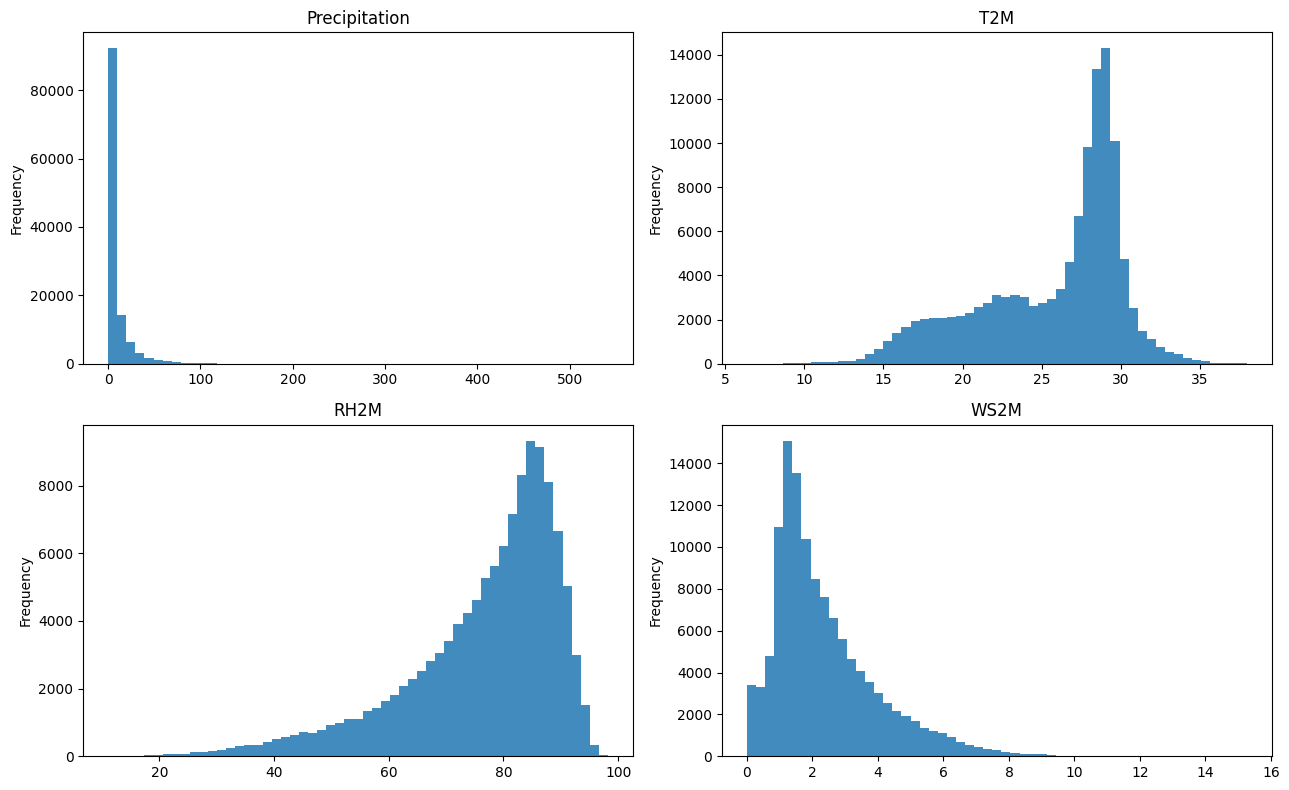

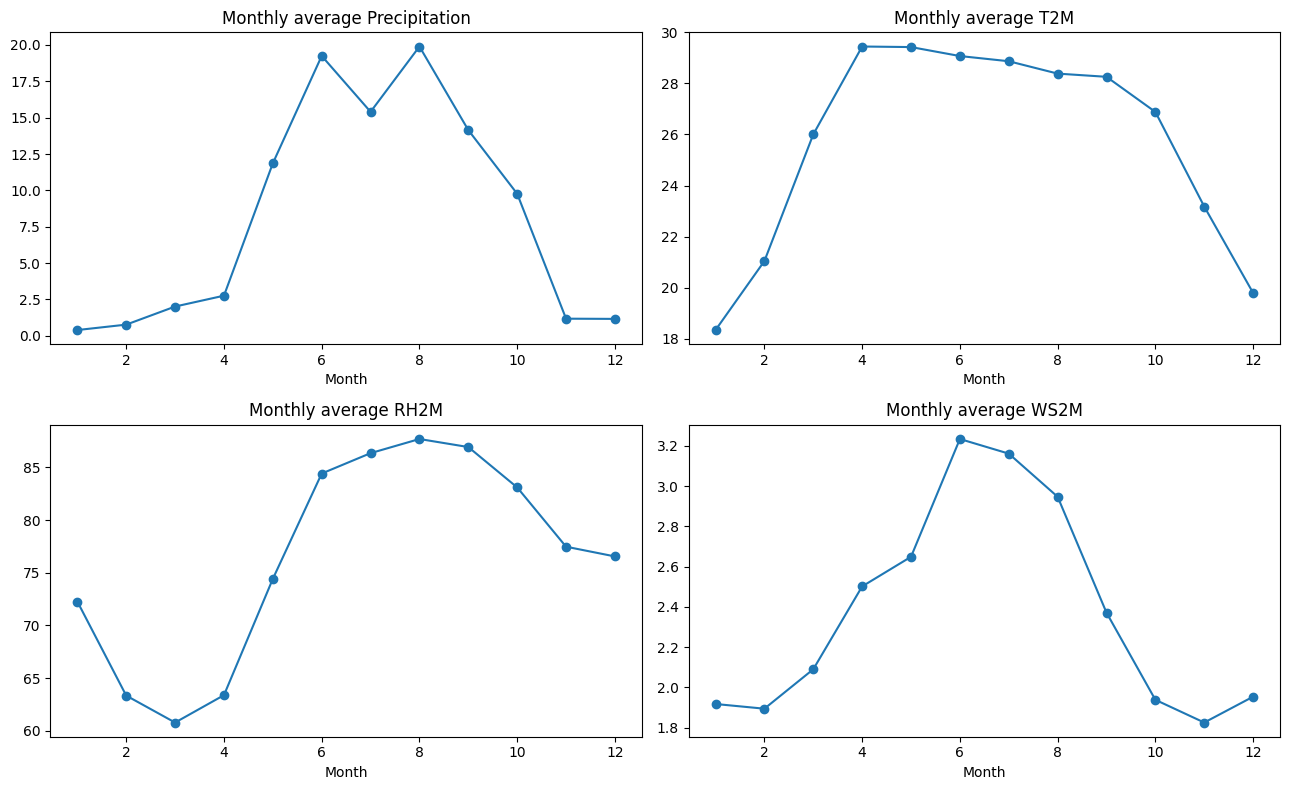

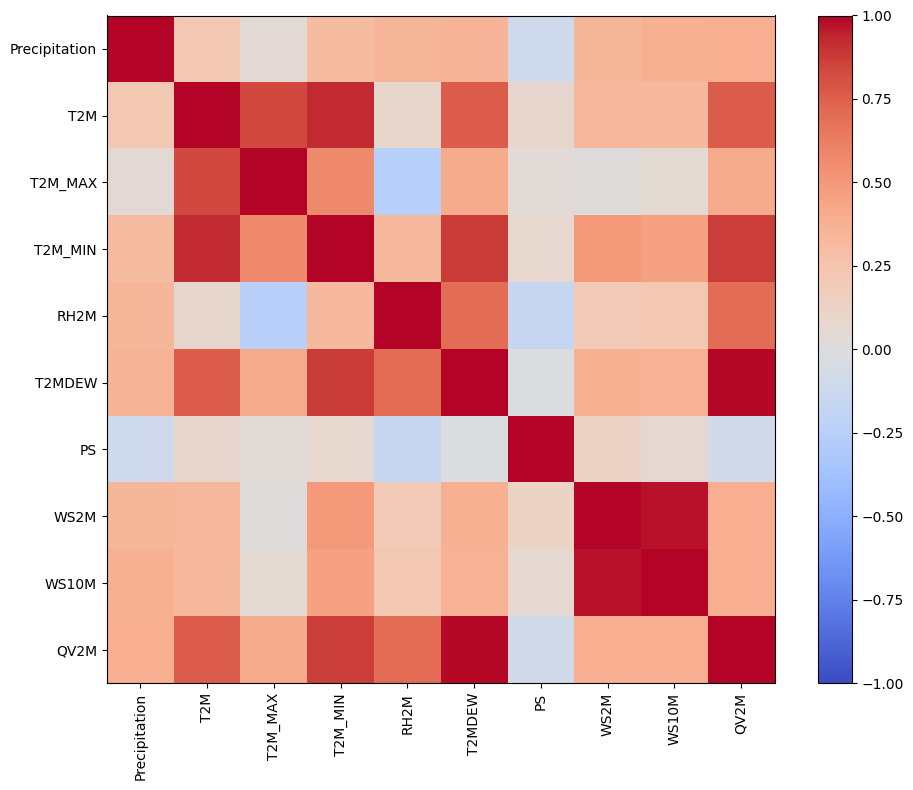

/tmp/ipykernel_22/725823126.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  z=adfuller(g[col].to_numpy(),autolag='AIC')
/tmp/ipykernel_22/725823126.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  z=adfuller(g[col].to_numpy(),autolag='AIC')
/tmp/ipykernel_22/725823126.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store

,LATITUDE,LONGITUDE,Variable,ADF_statistic,p_value,stationary_at_5pct
0,20.5,88.750,Precipitation,-4.326446,3.996321e-04,True
1,20.5,88.750,T2M,-2.138169,2.294461e-01,False
2,20.5,88.750,RH2M,-3.191375,2.048940e-02,True
3,20.5,88.750,WS2M,-4.108364,9.381491e-04,True
4,20.5,89.375,Precipitation,-4.347385,3.673705e-04,True
5,20.5,89.375,T2M,-2.240144,1.919994e-01,False
6,20.5,89.375,RH2M,-3.171561,2.169098e-02,True
7,20.5,89.375,WS2M,-4.132881,8.541674e-04,True
8,20.5,90.000,Precipitation,-3.487910,8.303086e-03,True
9,20.5,90.000,T2M,-2.333363,1.614333e-01,False


In [4]:
fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,c in zip(axes.flat,['Precipitation','T2M','RH2M','WS2M']):
    vals=full[c].to_numpy()
    ax.hist(vals,bins=55,alpha=.85); ax.set_title(c); ax.set_ylabel('Frequency')
plt.tight_layout();plt.savefig(OUT/'eda_distributions.png',dpi=180);plt.show()
monthly=full.groupby('MONTH')[['Precipitation','T2M','RH2M','WS2M']].mean()
fig,axs=plt.subplots(2,2,figsize=(13,8))
for ax,c in zip(axs.flat,monthly.columns):
    ax.plot(monthly.index,monthly[c],marker='o');ax.set_title('Monthly average '+c);ax.set_xlabel('Month')
plt.tight_layout();plt.savefig(OUT/'eda_monthly_seasonality.png',dpi=180);plt.show()
corr=full[weather_cols].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=90);ax.set_yticks(range(len(corr)),corr.index)
fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'eda_correlation.png',dpi=180);plt.show()
try:
    from statsmodels.tsa.stattools import adfuller
    adf_rows=[]
    for (lat,lon),g in list(full.groupby(['LATITUDE','LONGITUDE']))[:5]:
        for col in ['Precipitation','T2M','RH2M','WS2M']:
            z=adfuller(g[col].to_numpy(),autolag='AIC')
            adf_rows.append({'LATITUDE':lat,'LONGITUDE':lon,'Variable':col,'ADF_statistic':z[0],
                             'p_value':z[1],'stationary_at_5pct':z[1]<.05})
    adf_df=pd.DataFrame(adf_rows);display(adf_df);adf_df.to_csv(OUT/'adf_sample_5_locations.csv',index=False)
except ImportError:
    print('Optional ADF: pip install statsmodels')

4. Feature engineering. A feature at day t can use observations through day t ONLY.
Target is t+1. Targets and location keys remain in original units.

In [5]:
def make_features(g):
    g=g.sort_values('DATE').copy()
    g['LOC_LAT']=g['LATITUDE']; g['LOC_LON']=g['LONGITUDE']
    day=g.DATE.dt.dayofyear.to_numpy()
    g['DOY_SIN']=np.sin(2*np.pi*(day-1)/365.25)
    g['DOY_COS']=np.cos(2*np.pi*(day-1)/365.25)
    g['MONSOON']=g.DATE.dt.month.between(6,9).astype(int)
    for lag in [1,7,14,30]:g[f'RAIN_LAG_{lag}']=g.Precipitation.shift(lag)
    for w in [7,14,30]:g[f'RAIN_SUM_{w}']=g.Precipitation.rolling(w,min_periods=w).sum()
    for c in ['T2M','RH2M','WS2M']:
        g[c+'_DELTA']=g[c].diff()
        g[c+'_MEAN_7']=g[c].rolling(7,min_periods=7).mean()
    dry=g.Precipitation.lt(RAIN_OCC_MM).astype(int)
    g['DRY_STREAK']=dry.groupby((dry==0).cumsum()).cumsum()
    return g
fe=pd.concat([make_features(g) for _,g in full.groupby(['LATITUDE','LONGITUDE'])],ignore_index=True)
base_features=['LATITUDE','LONGITUDE','Precipitation','T2M','T2M_MAX','T2M_MIN','RH2M',
               'T2MDEW','PS','WS2M','WS10M','QV2M']
extra_features=['DOY_SIN','DOY_COS','MONSOON']+[f'RAIN_LAG_{l}' for l in [1,7,14,30]]+\
               [f'RAIN_SUM_{w}' for w in [7,14,30]]+\
               [c+'_DELTA' for c in ['T2M','RH2M','WS2M']]+\
               [c+'_MEAN_7' for c in ['T2M','RH2M','WS2M']]+['DRY_STREAK']
features=base_features+extra_features
# Starting 30 days with insufficient lag history have no engineered inputs.
fe=fe.dropna(subset=features).sort_values(keys).reset_index(drop=True)
print('Feature count:',len(features),'engineered rows:',len(fe))

Feature count: 29 engineered rows: 118773


5. Rain event definition: >=1 mm/day; extreme: > location-wise TRAINING wet-day P95.
All scalers fit on training ONLY. Transform rain regression with log1p before StandardScaler.

In [6]:
wet_train=full[(full.DATE<TRAIN_END)&(full.Precipitation>=RAIN_OCC_MM)]
thresholds=wet_train.groupby(['LATITUDE','LONGITUDE']).Precipitation.quantile(.95)
assert len(thresholds)==len(complete_pairs),'Some stations lack wet-day training observations.'
thresholds.rename('EXTREME_RAIN_MM').to_csv(OUT/'train_station_extreme_thresholds.csv')
feature_scaler=MinMaxScaler()
train_rows=fe.DATE.lt(TRAIN_END)
feature_scaler.fit(fe.loc[train_rows,features]);
fe_scaled=feature_scaler.transform(fe[features]).astype('float32')
# Physically meaningful targets (unscaled) taken DIRECTLY from same original rows.
reg_cols=['Precipitation','T2M','RH2M','WS2M']
reg_raw=fe[reg_cols].to_numpy(dtype=np.float32)
reg_transformed=reg_raw.copy()
reg_transformed[:,0]=np.log1p(np.maximum(reg_transformed[:,0],0))
target_scaler=StandardScaler().fit(reg_transformed[train_rows.to_numpy()])
reg_scaled=target_scaler.transform(reg_transformed).astype('float32')
np.savez(OUT/'scaler_parameters.npz',x_min=feature_scaler.data_min_,x_max=feature_scaler.data_max_,
         y_mean=target_scaler.mean_,y_scale=target_scaler.scale_)
pd.Series(features,name='feature').to_csv(OUT/'feature_names.csv',index=False)

6. Generate contiguous 30-day historical windows for NEXT-day prediction.
Samples assigned by TARGET DATE, not by last input date. 2023/2024 context may use earlier past.

In [7]:
X_list=[];yr_list=[];ye_list=[];yo_list=[];meta_rows=[]
for (lat,lon),group in fe.groupby(['LOC_LAT','LOC_LON'],sort=True):
    idx=group.index.to_numpy();days=group.DATE.to_numpy(dtype='datetime64[D]')
    threshold=float(thresholds.loc[(lat,lon)])
    for j in range(LOOKBACK,len(idx)):
        dates=days[j-LOOKBACK:j+1]
        if not np.all(np.diff(dates).astype('timedelta64[D]').astype(int)==1):continue
        target_i=idx[j]; start_ids=idx[j-LOOKBACK:j]
        rain=float(reg_raw[target_i,0]);
        X_list.append(fe_scaled[start_ids]);yr_list.append(reg_scaled[target_i]);
        yo_list.append(float(rain>=RAIN_OCC_MM));ye_list.append(float(rain>threshold))
        meta_rows.append({'DATE':pd.Timestamp(days[j]),'LATITUDE':lat,'LONGITUDE':lon,
                          'EXTREME_THRESHOLD':threshold,
                          'PREV_RAIN':float(reg_raw[idx[j-1],0]),
                          'PREV_TEMP':float(reg_raw[idx[j-1],1]),
                          'PREV_HUMIDITY':float(reg_raw[idx[j-1],2]),
                          'PREV_WIND':float(reg_raw[idx[j-1],3]),
                          'DRY_STREAK':float(fe.loc[idx[j-1],'DRY_STREAK'])})
X=np.asarray(X_list,dtype=np.float32);y_reg=np.asarray(yr_list,dtype=np.float32)
y_occ=np.asarray(yo_list,dtype=np.float32).reshape(-1,1)
y_ext=np.asarray(ye_list,dtype=np.float32).reshape(-1,1)
meta=pd.DataFrame(meta_rows)
train=meta.DATE.lt(TRAIN_END).to_numpy();val=meta.DATE.ge(TRAIN_END).to_numpy()&meta.DATE.lt(VAL_END).to_numpy()
test=meta.DATE.ge(VAL_END).to_numpy()
assert sum([train.sum(),val.sum(),test.sum()])==len(meta)
assert X.shape[1:]==(LOOKBACK,len(features))
assert np.isfinite(X).all() and np.isfinite(y_reg).all()
np.save(OUT/'X.npy',X);np.savez(OUT/'targets_and_splits.npz',y_reg=y_reg,y_occ=y_occ,y_ext=y_ext,train=train,val=val,test=test)
meta.to_csv(OUT/'sample_metadata.csv',index=False)
print('X:',X.shape,'Y regression:',y_reg.shape)
for name,mask in [('TRAIN',train),('VAL',val),('TEST',test)]:
    print(f'{name}: n={mask.sum():,}, rainy={y_occ[mask].mean():.2%}, extreme={y_ext[mask].mean():.2%}, '
          f'{meta.loc[mask,"DATE"].min().date()} to {meta.loc[mask,"DATE"].max().date()}')

X: (116283, 30, 29) Y regression: (116283, 4)
TRAIN: n=55,610, rainy=56.49%, extreme=2.90%, 2021-03-02 to 2022-12-31
VAL: n=30,295, rainy=49.36%, extreme=2.96%, 2023-01-01 to 2023-12-31
TEST: n=30,378, rainy=52.38%, extreme=4.74%, 2024-01-01 to 2024-12-31


7. Metrics and climatology/persistence baselines. DO NOT select neural models using test performance.

In [8]:
def inverse_reg(z):
    a=target_scaler.inverse_transform(np.asarray(z))
    a[:,0]=np.expm1(a[:,0]); a[:,0]=np.maximum(0,a[:,0]);
    a[:,2]=np.clip(a[:,2],0,100);a[:,3]=np.maximum(0,a[:,3]);return a
true_phys=inverse_reg(y_reg)
def reg_scores(y,p):
    mse=mean_squared_error(y,p)
    return {'MAE':mean_absolute_error(y,p),'MSE':mse,'RMSE':np.sqrt(mse),'R2':r2_score(y,p)}
def cls_scores(y,p,th=.5):
    y=np.asarray(y).ravel().astype(int);p=np.asarray(p).ravel();lab=(p>=th).astype(int)
    d={'Accuracy':accuracy_score(y,lab),'Precision':precision_score(y,lab,zero_division=0),
       'Recall':recall_score(y,lab,zero_division=0),'F1':f1_score(y,lab,zero_division=0)}
    d['ROC_AUC']=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan
    d['PR_AUC']=average_precision_score(y,p) if len(np.unique(y))==2 else np.nan
    return d
base_reg=[]
for i,c in enumerate(['Rainfall','Temperature','Humidity','Wind Speed']):
    pred=meta.loc[test,['PREV_RAIN','PREV_TEMP','PREV_HUMIDITY','PREV_WIND'][i]].to_numpy()
    base_reg.append({'Model':'Persistence','Target':c,**reg_scores(true_phys[test,i],pred)})
base_occ=(meta.loc[test,'PREV_RAIN'].to_numpy()>=RAIN_OCC_MM).astype(float)
base_ext=(meta.loc[test,'PREV_RAIN'].to_numpy()>meta.loc[test,'EXTREME_THRESHOLD'].to_numpy()).astype(float)
base_cls=[{'Model':'Persistence','Task':'Occurrence',**cls_scores(y_occ[test],base_occ)},
          {'Model':'Persistence','Task':'Extreme',**cls_scores(y_ext[test],base_ext)}]
display(pd.DataFrame(base_reg));display(pd.DataFrame(base_cls))

,Model,Target,MAE,MSE,RMSE,R2
0,Persistence,Rainfall,7.353157,460.487872,21.458981,0.133979
1,Persistence,Temperature,0.514346,0.515655,0.718091,0.977987
2,Persistence,Humidity,3.309117,22.452060,4.738361,0.880217
3,Persistence,Wind Speed,0.529129,0.690454,0.830936,0.764370


,Model,Task,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Persistence,Occurrence,0.886135,0.891038,0.891654,0.891346,0.885859,0.851249
1,Persistence,Extreme,0.943578,0.405274,0.405274,0.405274,0.687829,0.192458


8. Three architecture implementations, exactly the same samples/targets for each.
Class imbalance: moderate training-only positive weighting for extreme task, capped at 5.
Tuned thresholds selected on VALIDATION F1; TEST used only for evaluation.

In [9]:
if RUN_TRAINING:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(SEED)
    from tensorflow.keras import layers as L, Model
    class PositionalEncoding(L.Layer):
        def call(self,x):
            t=tf.cast(tf.range(tf.shape(x)[1])[:,None],tf.float32)
            d=tf.cast(tf.range(tf.shape(x)[2])[None,:],tf.float32)
            a=t/tf.pow(10000.,2*tf.floor(d/2)/tf.cast(tf.shape(x)[2],tf.float32))
            even=tf.cast(tf.equal(tf.math.mod(tf.cast(d,tf.int32),2),0),tf.float32)
            pe=even*tf.sin(a)+(1-even)*tf.cos(a)
            return x+pe[None,:,:]
    def attention_block(x,dim=48,drop=.2):
        a=L.MultiHeadAttention(num_heads=4,key_dim=12,dropout=drop)(x,x)
        x=L.LayerNormalization()(x+L.Dropout(drop)(a))
        f=L.Dense(96,activation='gelu')(x);f=L.Dropout(drop)(f);f=L.Dense(dim)(f)
        return L.LayerNormalization()(x+L.Dropout(drop)(f))
    def build_model(kind):
        inp=L.Input(shape=(LOOKBACK,len(features)))
        if kind=='LSTM':
            z=L.LSTM(64,return_sequences=True,dropout=.15)(inp)
            z=L.LSTM(32,dropout=.15)(z)
        elif kind=='Transformer':
            z=L.Dense(48)(inp);z=PositionalEncoding()(z)
            z=attention_block(z);z=attention_block(z)
            z=L.GlobalAveragePooling1D()(z)
        elif kind=='Hybrid':
            z=L.LSTM(48,return_sequences=True,dropout=.15)(inp)
            z=PositionalEncoding()(z)
            z=attention_block(z);z=L.GlobalAveragePooling1D()(z)
        else:raise ValueError(kind)
        z=L.Dense(48,activation='relu')(z);z=L.Dropout(.25)(z)
        reg=L.Dense(4,name='reg')(z)
        occ=L.Dense(1,activation='sigmoid',name='occ')(z)
        ext=L.Dense(1,activation='sigmoid',name='ext')(z)
        model=Model(inp,{'reg':reg,'occ':occ,'ext':ext})
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4,clipnorm=1.0),
                      loss={'reg':'mse','occ':'binary_crossentropy','ext':'binary_crossentropy'},
                      loss_weights={'reg':1.0,'occ':.5,'ext':.7})
        return model
    train_prev=float(y_ext[train].mean())
    pos_weight=min(5.0,max(1.0,(1-train_prev)/max(train_prev,1e-6)))
    weights={'reg':np.ones((train.sum(),),dtype='float32'),
             'occ':np.ones((train.sum(),),dtype='float32'),
             'ext':np.where(y_ext[train].ravel()>0,pos_weight,1).astype('float32')}
    print('Extreme training prevalence:',train_prev,'positive sample weight:',pos_weight)

Extreme training prevalence: 0.028987592086195946 positive sample weight: 5.0



========== TRAINING LSTM ==========


I0000 00:00:1792077558.325314      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792077558.329122      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/60
218/218 - 10s - 46ms/step - ext_loss: 0.4635 - loss: 1.1844 - occ_loss: 0.5242 - reg_loss: 0.5970 - val_ext_loss: 0.2101 - val_loss: 0.7822 - val_occ_loss: 0.4569 - val_reg_loss: 0.4049 - learning_rate: 5.0000e-04
Epoch 2/60
218/218 - 3s - 14ms/step - ext_loss: 0.3963 - loss: 0.9352 - occ_loss: 0.4074 - reg_loss: 0.4539 - val_ext_loss: 0.1864 - val_loss: 0.7208 - val_occ_loss: 0.4302 - val_reg_loss: 0.3733 - learning_rate: 5.0000e-04
Epoch 3/60
218/218 - 3s - 14ms/step - ext_loss: 0.3850 - loss: 0.8700 - occ_loss: 0.3826 - reg_loss: 0.4089 - val_ext_loss: 0.1724 - val_loss: 0.6976 - val_occ_loss: 0.4296 - val_reg_loss: 0.3601 - learning_rate: 5.0000e-04
Epoch 4/60
218/218 - 3s - 13ms/step - ext_loss: 0.3779 - loss: 0.8334 - occ_loss: 0.3696 - reg_loss: 0.3840 - val_ext_loss: 0.1750 - val_loss: 0.7085 - val_occ_loss: 0.4473 - val_reg_loss: 0.3603 - learning_rate: 5.0000e-04
Epoch 5/60
218/218 - 3s - 14ms/step - ext_loss: 0.3722 - loss: 0.8088 - occ_loss: 0.3609 - reg_loss: 0.

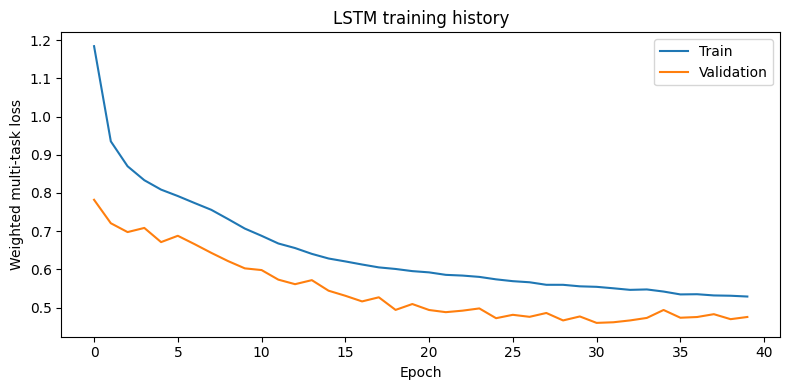

Validation-selected thresholds: {'occ': 0.45000000000000007, 'ext': 0.38000000000000006}

========== TRAINING Transformer ==========
Epoch 1/60


I0000 00:00:1792077710.195194      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


218/218 - 35s - 162ms/step - ext_loss: 0.4311 - loss: 1.1005 - occ_loss: 0.4821 - reg_loss: 0.5568 - val_ext_loss: 0.1884 - val_loss: 0.6489 - val_occ_loss: 0.4027 - val_reg_loss: 0.3145 - learning_rate: 5.0000e-04
Epoch 2/60
218/218 - 2s - 10ms/step - ext_loss: 0.3727 - loss: 0.7662 - occ_loss: 0.3596 - reg_loss: 0.3252 - val_ext_loss: 0.1476 - val_loss: 0.5077 - val_occ_loss: 0.3615 - val_reg_loss: 0.2225 - learning_rate: 5.0000e-04
Epoch 3/60
218/218 - 2s - 10ms/step - ext_loss: 0.3276 - loss: 0.6614 - occ_loss: 0.3235 - reg_loss: 0.2704 - val_ext_loss: 0.1378 - val_loss: 0.4559 - val_occ_loss: 0.3232 - val_reg_loss: 0.1966 - learning_rate: 5.0000e-04
Epoch 4/60
218/218 - 2s - 10ms/step - ext_loss: 0.3051 - loss: 0.6086 - occ_loss: 0.3034 - reg_loss: 0.2434 - val_ext_loss: 0.1316 - val_loss: 0.4368 - val_occ_loss: 0.3140 - val_reg_loss: 0.1864 - learning_rate: 5.0000e-04
Epoch 5/60
218/218 - 2s - 10ms/step - ext_loss: 0.2973 - loss: 0.5833 - occ_loss: 0.2913 - reg_loss: 0.2294 - val

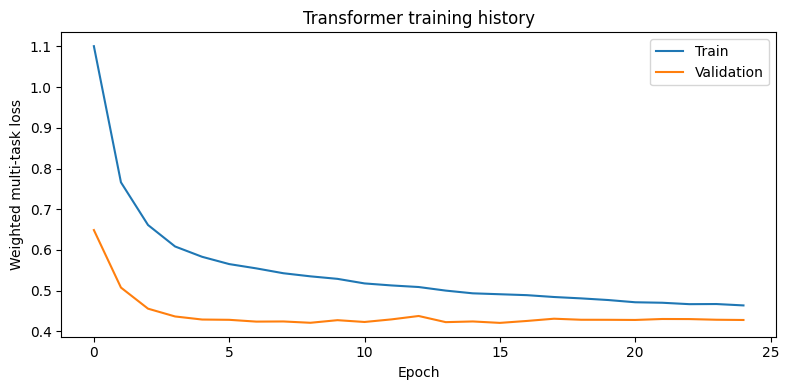

Validation-selected thresholds: {'occ': 0.42000000000000004, 'ext': 0.30000000000000004}

========== TRAINING Hybrid ==========
Epoch 1/60
218/218 - 10s - 47ms/step - ext_loss: 0.4275 - loss: 1.1524 - occ_loss: 0.4859 - reg_loss: 0.6098 - val_ext_loss: 0.1849 - val_loss: 0.7479 - val_occ_loss: 0.4371 - val_reg_loss: 0.3978 - learning_rate: 5.0000e-04
Epoch 2/60
218/218 - 4s - 19ms/step - ext_loss: 0.3903 - loss: 0.9347 - occ_loss: 0.4044 - reg_loss: 0.4592 - val_ext_loss: 0.1735 - val_loss: 0.7097 - val_occ_loss: 0.4330 - val_reg_loss: 0.3697 - learning_rate: 5.0000e-04
Epoch 3/60
218/218 - 4s - 19ms/step - ext_loss: 0.3781 - loss: 0.8557 - occ_loss: 0.3765 - reg_loss: 0.4026 - val_ext_loss: 0.1547 - val_loss: 0.5890 - val_occ_loss: 0.3708 - val_reg_loss: 0.2936 - learning_rate: 5.0000e-04
Epoch 4/60
218/218 - 4s - 19ms/step - ext_loss: 0.3349 - loss: 0.7565 - occ_loss: 0.3367 - reg_loss: 0.3537 - val_ext_loss: 0.1461 - val_loss: 0.5221 - val_occ_loss: 0.3340 - val_reg_loss: 0.2511 - l

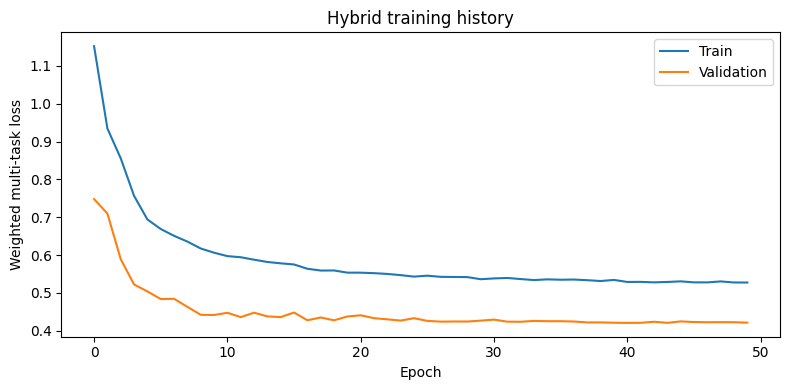

Validation-selected thresholds: {'occ': 0.44000000000000006, 'ext': 0.35000000000000003}


In [10]:
models={}; histories={}; predictions={}; thresholds_by_model={}
if RUN_TRAINING:
    for name in ['LSTM','Transformer','Hybrid']:
        print('\n========== TRAINING',name,'==========')
        tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(SEED)
        m=build_model(name)
        ckpt=OUT/f'{name}_best.keras'
        history=m.fit(X[train],{'reg':y_reg[train],'occ':y_occ[train],'ext':y_ext[train]},
              sample_weight=weights,
              validation_data=(X[val],{'reg':y_reg[val],'occ':y_occ[val],'ext':y_ext[val]}),
              epochs=MAX_EPOCHS,batch_size=BATCH,verbose=2,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=9,restore_best_weights=True),
                         tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.5,patience=4,min_lr=1e-5),
                         tf.keras.callbacks.ModelCheckpoint(str(ckpt),monitor='val_loss',save_best_only=True)])
        models[name]=m;histories[name]=history.history
        pd.DataFrame(history.history).to_csv(OUT/f'{name}_training_history.csv',index=False)
        fig,ax=plt.subplots(figsize=(8,4));ax.plot(history.history['loss'],label='Train')
        ax.plot(history.history['val_loss'],label='Validation');ax.set_title(name+' training history')
        ax.set_xlabel('Epoch');ax.set_ylabel('Weighted multi-task loss');ax.legend();fig.tight_layout()
        fig.savefig(OUT/f'{name}_loss.png',dpi=180);plt.show()
        pv=m.predict(X[val],batch_size=512,verbose=0)
        ptest=m.predict(X[test],batch_size=512,verbose=0)
        def choose_thr(y,p):
            options=np.arange(.05,.951,.01)
            f=[f1_score(y.ravel().astype(int),(p.ravel()>=z).astype(int),zero_division=0) for z in options]
            return float(options[int(np.argmax(f))])
        th_occ=choose_thr(y_occ[val],pv['occ']);th_ext=choose_thr(y_ext[val],pv['ext'])
        thresholds_by_model[name]={'occ':th_occ,'ext':th_ext}
        predictions[name]=ptest
        print('Validation-selected thresholds:',thresholds_by_model[name])
    with open(OUT/'validation_thresholds.json','w') as f:json.dump(thresholds_by_model,f,indent=2)

9. Final TEST report: rainfall, temperature, humidity, wind; event classification; full PNG graphs.
Threshold chosen from validation only. No tuned-on-test scores.

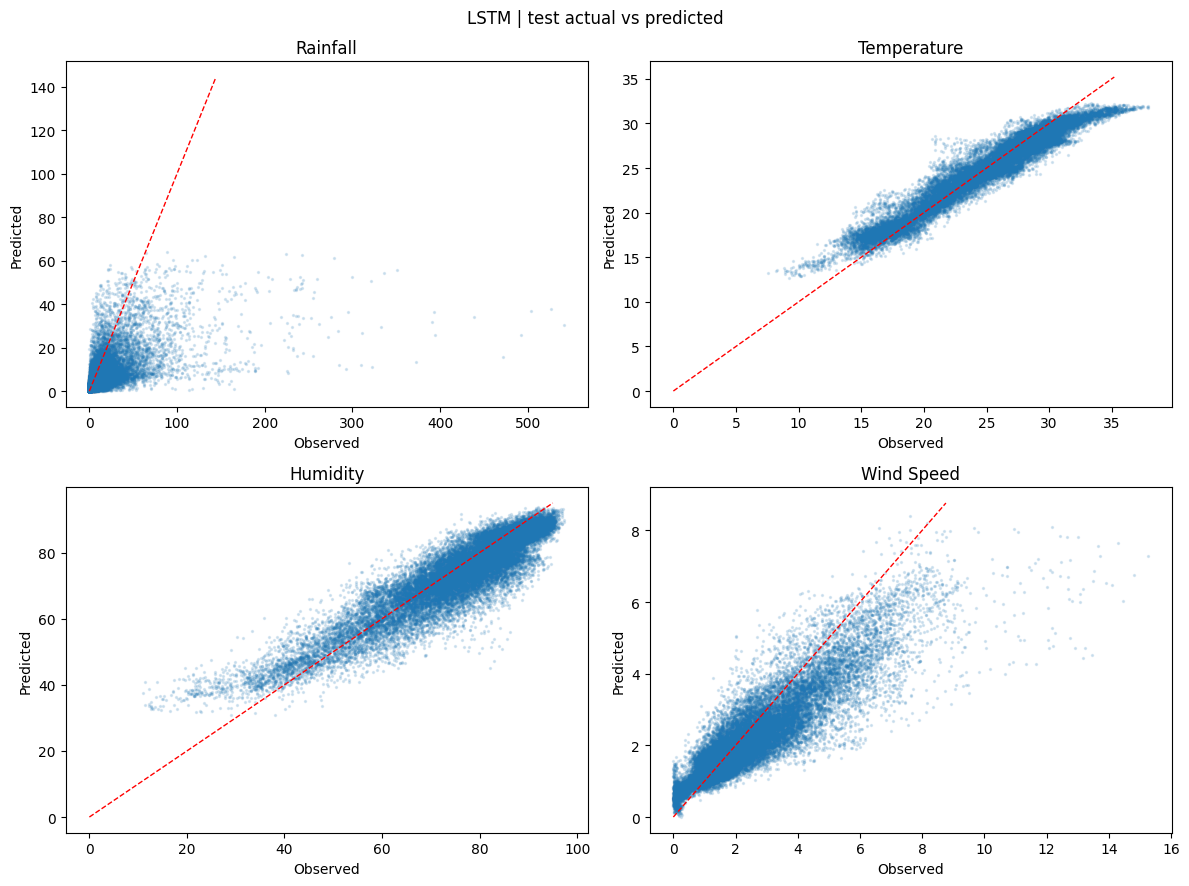

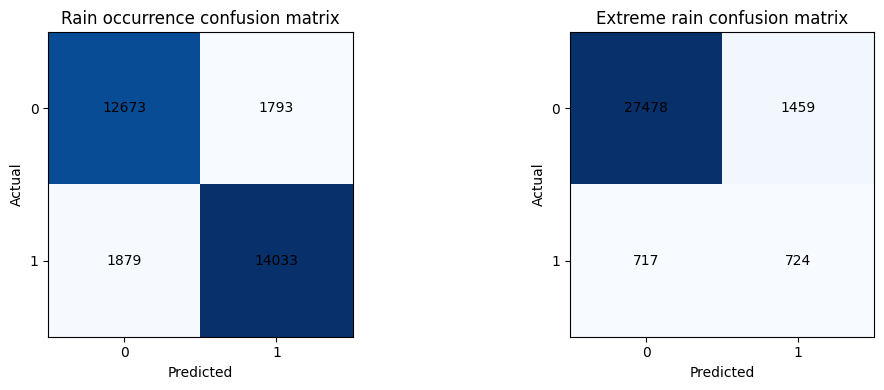

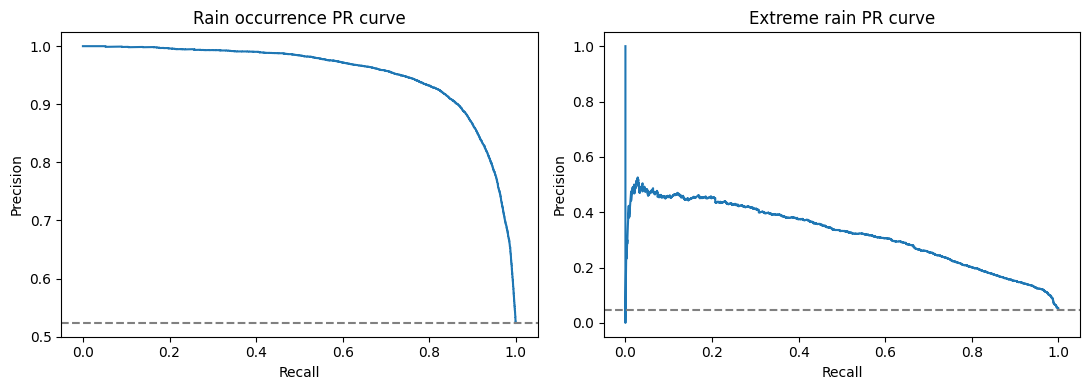

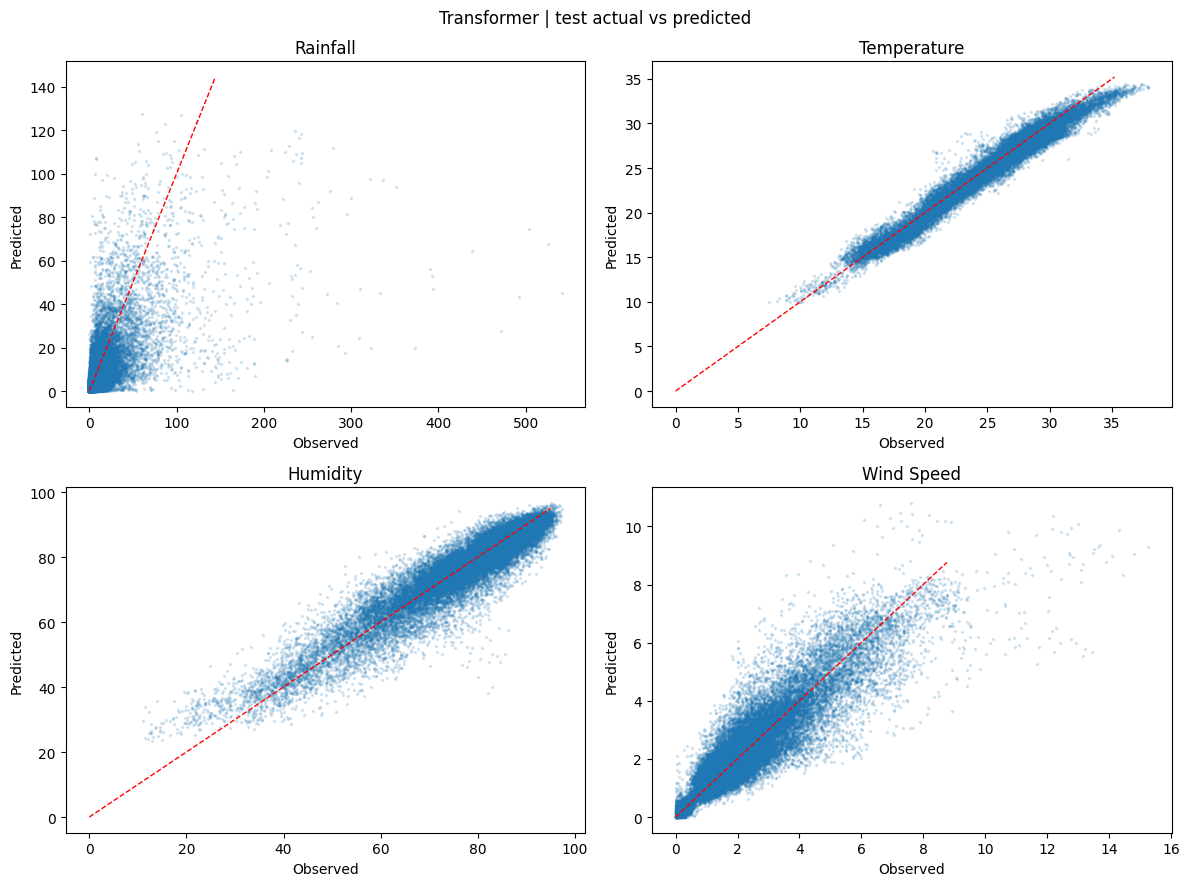

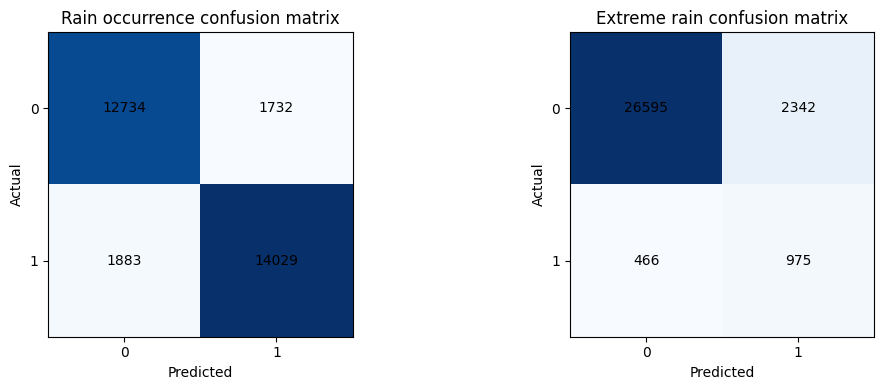

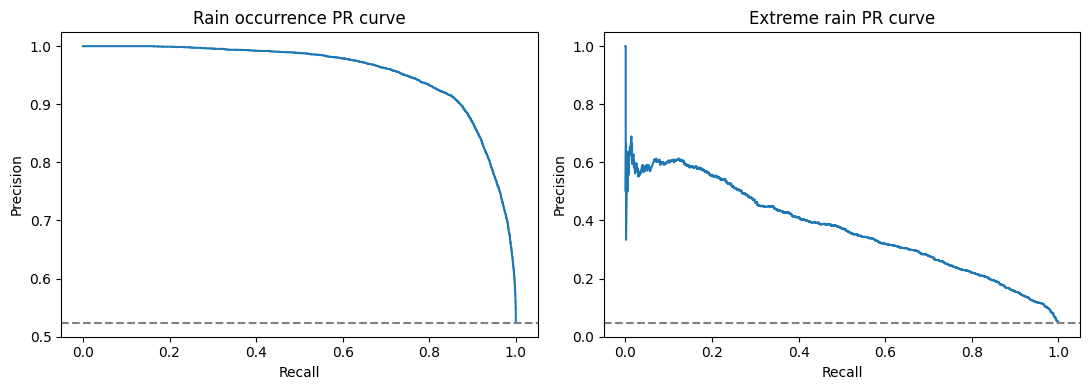

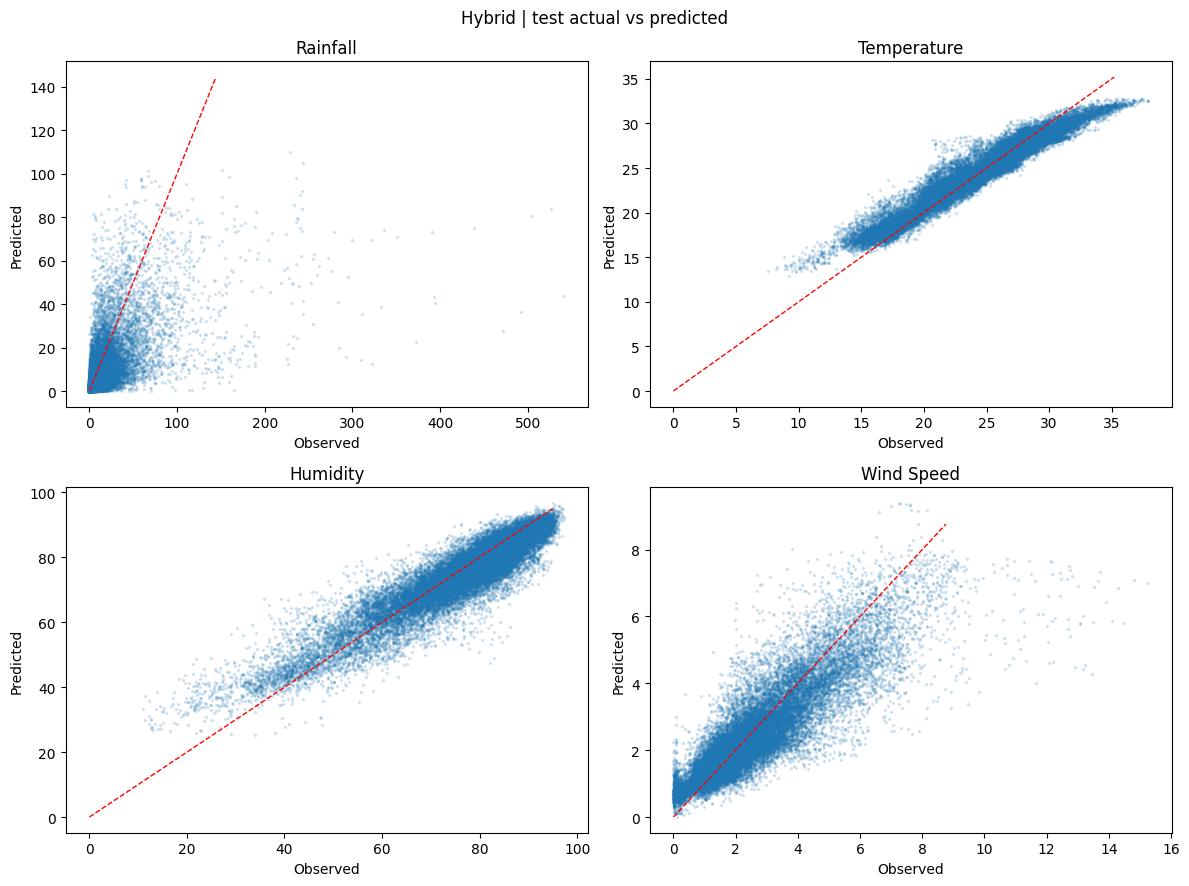

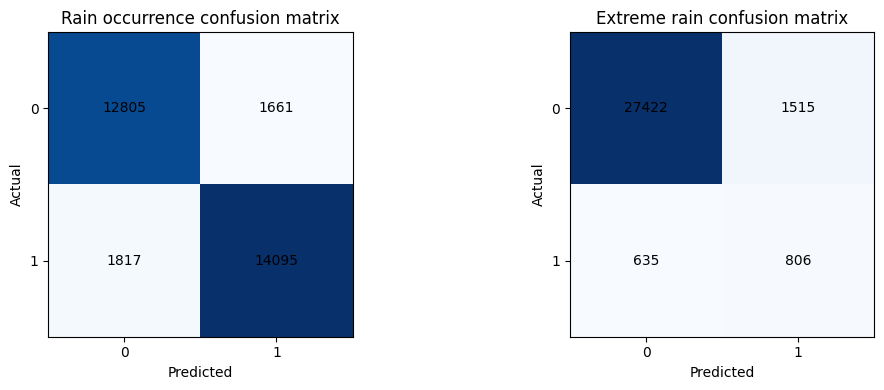

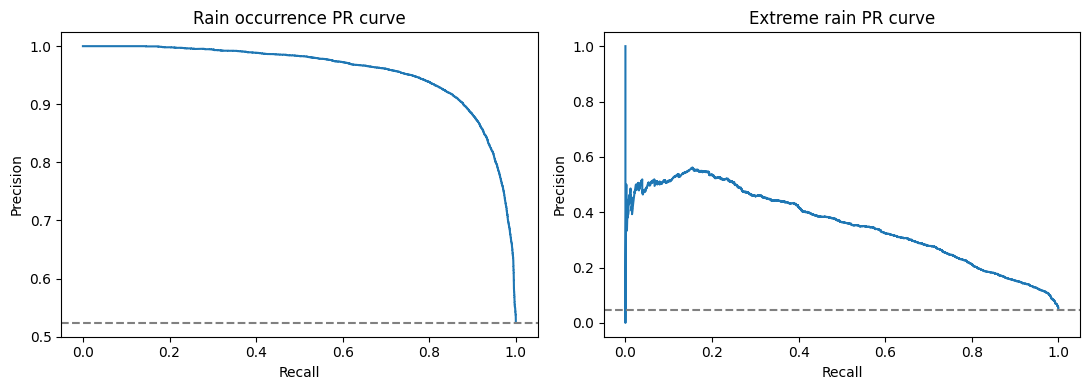


===== ALL MODELS REGRESSION =====


,Model,Target,MAE,MSE,RMSE,R2
0,Persistence,Rainfall,7.3532,460.4879,21.4590,0.1340
1,Persistence,Temperature,0.5143,0.5157,0.7181,0.9780
2,Persistence,Humidity,3.3091,22.4521,4.7384,0.8802
3,Persistence,Wind Speed,0.5291,0.6905,0.8309,0.7644
4,LSTM,Rainfall,6.5857,391.8905,19.7962,0.2630
5,LSTM,Temperature,1.0455,1.8915,1.3753,0.9193
6,LSTM,Humidity,4.3452,32.2594,5.6797,0.8279
7,LSTM,Wind Speed,0.5980,0.7954,0.8919,0.7285
8,Transformer,Rainfall,6.2174,317.2757,17.8122,0.4033
9,Transformer,Temperature,0.7150,0.8560,0.9252,0.9635



===== ALL MODELS CLASSIFICATION =====


,Model,Task,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Persistence,Occurrence,0.8861,0.8910,0.8917,0.8913,0.8859,0.8512
1,Persistence,Extreme,0.9436,0.4053,0.4053,0.4053,0.6878,0.1925
2,LSTM,Occurrence,0.8791,0.8867,0.8819,0.8843,0.9446,0.9526
3,LSTM,Extreme,0.9284,0.3317,0.5024,0.3996,0.9053,0.3217
4,Transformer,Occurrence,0.8810,0.8901,0.8817,0.8859,0.9480,0.9559
5,Transformer,Extreme,0.9076,0.2939,0.6766,0.4098,0.9100,0.3729
6,Hybrid,Occurrence,0.8855,0.8946,0.8858,0.8902,0.9509,0.9568
7,Hybrid,Extreme,0.9292,0.3473,0.5593,0.4285,0.9111,0.3557


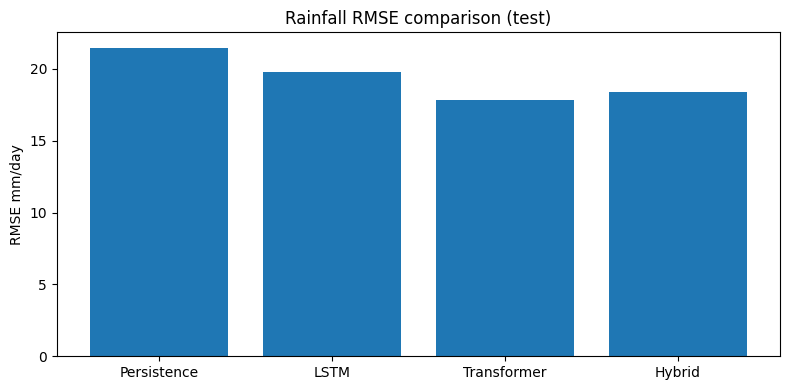

In [11]:
reg_table=base_reg.copy();cls_table=base_cls.copy()
if RUN_TRAINING:
    for name in ['LSTM','Transformer','Hybrid']:
        pred=predictions[name];physical=inverse_reg(pred['reg'])
        for k,c in enumerate(['Rainfall','Temperature','Humidity','Wind Speed']):
            reg_table.append({'Model':name,'Target':c,**reg_scores(true_phys[test,k],physical[:,k])})
        for task,key,truth in [('Occurrence','occ',y_occ[test]),('Extreme','ext',y_ext[test])]:
            cls_table.append({'Model':name,'Task':task,
                              **cls_scores(truth,pred[key],thresholds_by_model[name][key])})
        # one combined predictions file per model
        saved=meta.loc[test,['DATE','LATITUDE','LONGITUDE','EXTREME_THRESHOLD']].reset_index(drop=True).copy()
        for k,c in enumerate(['Rainfall','Temperature','Humidity','Wind']):
            saved[c+'_actual']=true_phys[test,k];saved[c+'_predicted']=physical[:,k]
        saved['occ_actual']=y_occ[test].ravel();saved['occ_prob']=pred['occ'].ravel()
        saved['ext_actual']=y_ext[test].ravel();saved['ext_prob']=pred['ext'].ravel()
        saved.to_csv(OUT/f'{name}_test_predictions.csv',index=False)
        fig,axs=plt.subplots(2,2,figsize=(12,9))
        for ax,(k,c) in zip(axs.flat,enumerate(['Rainfall','Temperature','Humidity','Wind Speed'])):
            ax.scatter(true_phys[test,k],physical[:,k],s=2,alpha=.15)
            lim=max(np.nanpercentile(true_phys[test,k],99.5),np.nanpercentile(physical[:,k],99.5))
            ax.plot([0,lim],[0,lim],'r--',lw=1);ax.set_title(c);ax.set_xlabel('Observed');ax.set_ylabel('Predicted')
        fig.suptitle(name+' | test actual vs predicted');fig.tight_layout()
        fig.savefig(OUT/f'{name}_actual_vs_predicted.png',dpi=180);plt.show()
        fig,axs=plt.subplots(1,2,figsize=(11,4))
        for ax,(task,key,y) in zip(axs,[('Rain occurrence','occ',y_occ[test]),('Extreme rain','ext',y_ext[test])]):
            cm=confusion_matrix(y.ravel().astype(int),
                                (pred[key].ravel()>=thresholds_by_model[name][key]).astype(int),labels=[0,1])
            ax.imshow(cm,cmap='Blues');ax.set_title(task+' confusion matrix')
            ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_xticks([0,1]);ax.set_yticks([0,1])
            for i in [0,1]:
                for j in [0,1]:ax.text(j,i,str(cm[i,j]),ha='center',va='center')
        fig.tight_layout();fig.savefig(OUT/f'{name}_confusion_matrices.png',dpi=180);plt.show()
        fig,axs=plt.subplots(1,2,figsize=(11,4))
        for ax,(task,key,y) in zip(axs,[('Rain occurrence','occ',y_occ[test]),('Extreme rain','ext',y_ext[test])]):
            if len(np.unique(y))==2:
                precision,recall,_=precision_recall_curve(y,pred[key].ravel())
                ax.plot(recall,precision);ax.axhline(y.mean(),ls='--',color='gray')
            ax.set_title(task+' PR curve');ax.set_xlabel('Recall');ax.set_ylabel('Precision')
        fig.tight_layout();fig.savefig(OUT/f'{name}_precision_recall.png',dpi=180);plt.show()
reg_report=pd.DataFrame(reg_table);cls_report=pd.DataFrame(cls_table)
reg_report.to_csv(OUT/'all_models_regression.csv',index=False)
cls_report.to_csv(OUT/'all_models_classification.csv',index=False)
print('\n===== ALL MODELS REGRESSION =====');display(reg_report.round(4))
print('\n===== ALL MODELS CLASSIFICATION =====');display(cls_report.round(4))
if RUN_TRAINING:
    fig,ax=plt.subplots(figsize=(8,4))
    v=reg_report[reg_report.Target=='Rainfall'];ax.bar(v.Model,v.RMSE)
    ax.set_title('Rainfall RMSE comparison (test)');ax.set_ylabel('RMSE mm/day')
    fig.tight_layout();fig.savefig(OUT/'model_comparison_rainfall_rmse.png',dpi=180);plt.show()

10. Optional feature-time SHAP: depends on TensorFlow and installed shap version.
This is intentionally opt-in; if GradientExplainer cannot handle a TF version, report it, not fake values.

In [12]:
if RUN_TRAINING and RUN_SHAP:
    try:
        import shap
        selected=min(['LSTM','Transformer','Hybrid'],key=lambda n:float(np.min(histories[n]['val_loss'])))
        extreme_output=models[selected].get_layer('ext').output
        shap_model=tf.keras.Model(models[selected].inputs,extreme_output)
        background=X[train][:64]
        explain=X[test][:48]
        explainer=shap.GradientExplainer(shap_model,background)
        contributions=explainer.shap_values(explain)
        if isinstance(contributions,list):contributions=contributions[0]
        contributions=np.asarray(contributions)
        if contributions.ndim==4:contributions=contributions[...,0]
        if contributions.shape!=explain.shape:raise ValueError(f'Unexpected SHAP shape: {contributions.shape}')
        importances=np.abs(contributions).mean(axis=0)
        pd.DataFrame(importances,columns=features,index=[f'Lag-{LOOKBACK-i}' for i in range(LOOKBACK)]).to_csv(OUT/'temporal_shap_matrix.csv')
        fig,ax=plt.subplots(figsize=(15,7));im=ax.imshow(importances,aspect='auto')
        ax.set_yticks(range(LOOKBACK),[f'-{LOOKBACK-i}' for i in range(LOOKBACK)])
        ax.set_xticks(range(len(features)),features,rotation=90)
        ax.set_xlabel('Feature');ax.set_ylabel('Days before target');ax.set_title(selected+' temporal Gradient SHAP (absolute magnitude)')
        fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'temporal_shap_heatmap.png',dpi=180);plt.show()
    except Exception as exc:
        print('SHAP not computed; diagnose package/TF compatibility:',repr(exc))

11. WARI: transparent EXPERIMENTAL weather-hazard proxy, not a validated crop loss index.
Rain/exreme probability, dry streak, temperature stress and wind risk are used.

Selected via validation: Hybrid 
WARI class counts:
 Risk_Category
Low         28374
Moderate     2004
High            0
Name: count, dtype: int64


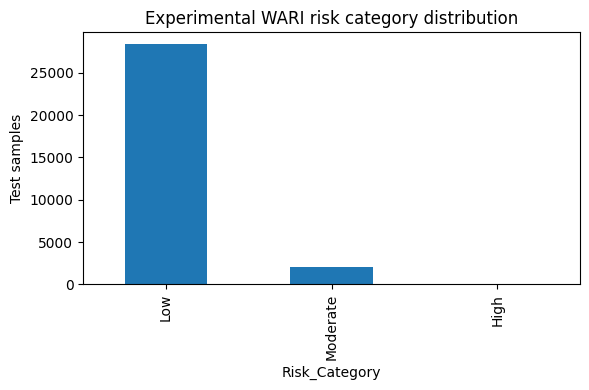


FINISHED. Outputs in: /kaggle/working/weatherxai_corrected_results


In [13]:
if RUN_TRAINING:
    # choose on validation loss, not test scores
    winner=min(histories,key=lambda n:min(histories[n]['val_loss']))
    pred=predictions[winner];p=inverse_reg(pred['reg']);mtest=meta.loc[test].reset_index(drop=True)
    train_temp=full.loc[full.DATE.lt(TRAIN_END),'T2M']
    train_wind=full.loc[full.DATE.lt(TRAIN_END),'WS2M']
    temp_z=np.clip((p[:,1]-train_temp.mean())/max(train_temp.std(),1e-6),0,3)/3
    wind_score=np.clip(p[:,3]/max(train_wind.quantile(.95),1e-6),0,1)
    rain_score=np.clip(p[:,0]/np.maximum(mtest.EXTREME_THRESHOLD.to_numpy(),1),0,1)
    dry_score=np.clip(mtest.DRY_STREAK.to_numpy()/15,0,1)*np.clip(1-pred['occ'].ravel(),0,1)
    components=np.column_stack([pred['ext'].ravel(),rain_score,dry_score,temp_z,wind_score])
    weights_wari=np.array([.35,.20,.20,.15,.10])  # illustrative, subject to sensitivity validation
    score=components@weights_wari
    w=mtest[['DATE','LATITUDE','LONGITUDE']].copy()
    w['model']=winner;w['WARI_experimental']=score
    w['Risk_Category']=pd.cut(score,[-np.inf,.33,.66,np.inf],labels=['Low','Moderate','High'])
    w.to_csv(OUT/'WARI_experimental_unvalidated.csv',index=False)
    print('Selected via validation:',winner,'\nWARI class counts:\n',w.Risk_Category.value_counts())
    fig,ax=plt.subplots(figsize=(6,4));w.Risk_Category.value_counts().reindex(['Low','Moderate','High'],fill_value=0).plot.bar(ax=ax)
    ax.set_title('Experimental WARI risk category distribution');ax.set_ylabel('Test samples')
    fig.tight_layout();fig.savefig(OUT/'WARI_risk_distribution.png',dpi=180);plt.show()
print('\nFINISHED. Outputs in:',OUT)

# Additional publication experiments: RQ3–RQ6
Run all earlier cells first in this **same notebook session**. This extension does not invent results. RQ3: matched Transformer single-task vs multi-task; RQ4–RQ5: genuine Gradient SHAP feature/time explanations; RQ6: sensitivity and internal-consistency diagnostics for illustrative WARI. **These do not establish externally validated crop-loss risk.** Use the same frozen 2024 test set, only after model selection.

This uses the original 83-station 2021–2024 benchmark, training through 2022, validating on 2023 and testing on 2024. Do not use test results to revise thresholds or architecture selection and then treat 2024 as untouched.

In [14]:
# RQ3-6 setup and output subfolders
from sklearn.metrics import brier_score_loss
from sklearn.metrics import ConfusionMatrixDisplay
RQ_OUT = OUT / 'rq3_rq6_evidence'
RQ_OUT.mkdir(parents=True, exist_ok=True)
assert RUN_TRAINING and all(n in models for n in ('LSTM','Transformer','Hybrid'))
assert X.shape[1] == 30 and X.shape[2] == len(features)
print('Evidence output folder:', RQ_OUT)
print('Available models:', list(models))


Evidence output folder: /kaggle/working/weatherxai_corrected_results/rq3_rq6_evidence
Available models: ['LSTM', 'Transformer', 'Hybrid']


## RQ3 — Matched ablation experiment
Regression-only Transformer and existing multi-task Transformer have the same backbone and same splits. A single-task rainfall model predicts continuous rainfall; its extreme alert is based on predicted rainfall exceeding each station's training-set wet-day P95. The multi-task model predicts extreme probability using its dedicated head. For binary alerts, decision thresholds are selected on **2023 validation**, not test. Continuous rainfall metrics and PR curves are also reported. This is one seed; multiple seeds/rolling folds are recommended before a publication claim.

Epoch 1/60
218/218 - 29s - 135ms/step - loss: 0.5248 - val_loss: 0.5966 - learning_rate: 5.0000e-04
Epoch 2/60
218/218 - 2s - 9ms/step - loss: 0.4291 - val_loss: 0.4449 - learning_rate: 5.0000e-04
Epoch 3/60
218/218 - 2s - 8ms/step - loss: 0.3530 - val_loss: 0.3764 - learning_rate: 5.0000e-04
Epoch 4/60
218/218 - 2s - 8ms/step - loss: 0.3214 - val_loss: 0.3552 - learning_rate: 5.0000e-04
Epoch 5/60
218/218 - 2s - 8ms/step - loss: 0.3102 - val_loss: 0.3492 - learning_rate: 5.0000e-04
Epoch 6/60
218/218 - 2s - 8ms/step - loss: 0.3048 - val_loss: 0.3451 - learning_rate: 5.0000e-04
Epoch 7/60
218/218 - 2s - 8ms/step - loss: 0.3002 - val_loss: 0.3469 - learning_rate: 5.0000e-04
Epoch 8/60
218/218 - 2s - 8ms/step - loss: 0.2973 - val_loss: 0.3441 - learning_rate: 5.0000e-04
Epoch 9/60
218/218 - 2s - 8ms/step - loss: 0.2938 - val_loss: 0.3499 - learning_rate: 5.0000e-04
Epoch 10/60
218/218 - 2s - 8ms/step - loss: 0.2900 - val_loss: 0.3604 - learning_rate: 5.0000e-04
Epoch 11/60
218/218 - 2s -

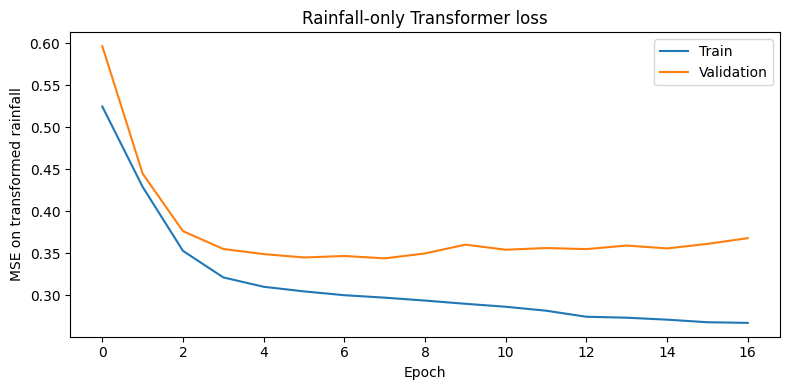

In [15]:
# Build matched *single-task rainfall-only* Transformer: same encoder family as existing model
import tensorflow as tf
from tensorflow.keras import layers as L

class RainfallOnlyTransformer(tf.keras.Model):
    def __init__(self, nfeat):
        super().__init__(name='RainfallOnlyTransformer')
        self.embed=L.Dense(48)
        self.pos=PositionalEncoding()
        self.att1=L.MultiHeadAttention(num_heads=4,key_dim=12,dropout=.2)
        self.norm1=L.LayerNormalization()
        self.ff1=tf.keras.Sequential([L.Dense(96,activation='gelu'),L.Dropout(.2),L.Dense(48)])
        self.norm2=L.LayerNormalization()
        self.att2=L.MultiHeadAttention(num_heads=4,key_dim=12,dropout=.2)
        self.norm3=L.LayerNormalization()
        self.ff2=tf.keras.Sequential([L.Dense(96,activation='gelu'),L.Dropout(.2),L.Dense(48)])
        self.norm4=L.LayerNormalization()
        self.pool=L.GlobalAveragePooling1D()
        self.hidden=L.Dense(48,activation='relu')
        self.drop=L.Dropout(.25)
        self.head=L.Dense(1)
    def call(self, inputs, training=False):
        z=self.pos(self.embed(inputs))
        a=self.att1(z,z,training=training)
        z=self.norm1(z+self.drop(a,training=training))
        z=self.norm2(z+self.drop(self.ff1(z,training=training),training=training))
        a=self.att2(z,z,training=training)
        z=self.norm3(z+self.drop(a,training=training))
        z=self.norm4(z+self.drop(self.ff2(z,training=training),training=training))
        z=self.pool(z)
        return self.head(self.drop(self.hidden(z),training=training))

# rainfall output in log1p+standardized units as in the existing notebook
RUN_RQ3_ABLATION = True
if RUN_RQ3_ABLATION:
    tf.keras.utils.set_random_seed(SEED)
    rain_only=RainfallOnlyTransformer(len(features))
    rain_only.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4,clipnorm=1.0),loss='mse')
    hist_rain=rain_only.fit(X[train],y_reg[train,0:1],validation_data=(X[val],y_reg[val,0:1]),
      epochs=MAX_EPOCHS,batch_size=BATCH,verbose=2,
      callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=9,restore_best_weights=True),
                 tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=4,factor=.5,min_lr=1e-5)])
    pd.DataFrame(hist_rain.history).to_csv(RQ_OUT/'single_task_training_history.csv',index=False)
    rain_only.save_weights(str(RQ_OUT/'rain_only_transformer.weights.h5'))
    fig,ax=plt.subplots(figsize=(8,4));ax.plot(hist_rain.history['loss'],label='Train');ax.plot(hist_rain.history['val_loss'],label='Validation')
    ax.set(xlabel='Epoch',ylabel='MSE on transformed rainfall',title='Rainfall-only Transformer loss');ax.legend();fig.tight_layout()
    fig.savefig(RQ_OUT/'rain_only_loss.png',dpi=180);plt.show()


,Method,Selected_on_validation,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Single-task rainfall -> threshold,0.552277,0.931826,0.351695,0.518390,0.419074,0.913039,0.334478
1,Event-aware multi-task Transformer,0.365124,0.919020,0.316264,0.608605,0.416232,0.910023,0.372915


,Method,MAE,MSE,RMSE,R2
0,Rainfall-only Transformer,6.416863,347.196260,18.633203,0.347042
1,Multi-task Transformer,6.217384,317.275665,17.812234,0.403313


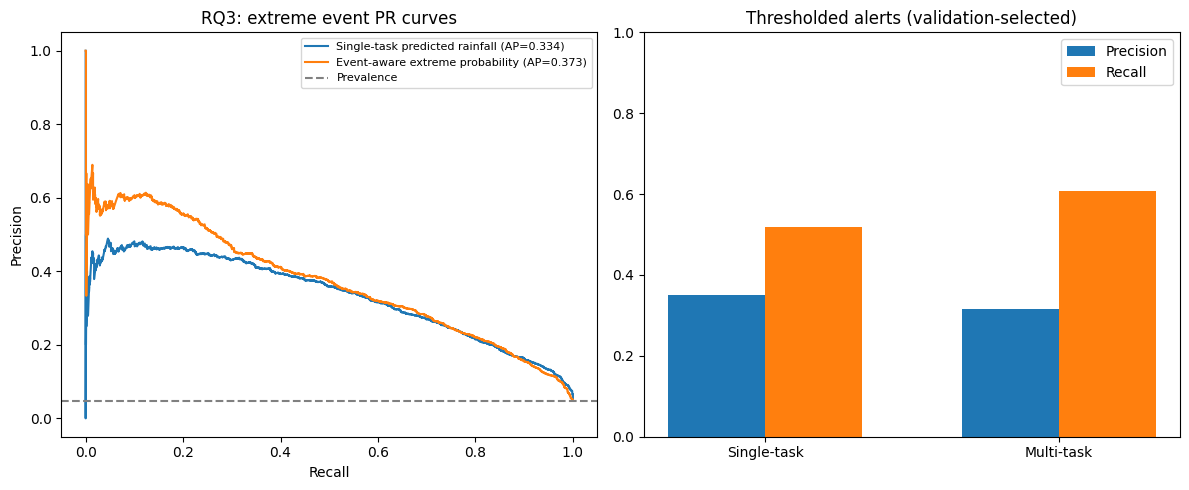

RQ3 thresholds selected on VALIDATION only: {'single': 0.5522767670349218, 'multi': 0.3651241645216942}


In [16]:
# Rain-only raw mm/day predictions, without using the other three targets
# (inverse target scaling via only the rainfall mean/scale)
def rainfall_to_mm(pred_z):
    v=np.asarray(pred_z).ravel()*target_scaler.scale_[0]+target_scaler.mean_[0]
    return np.maximum(0,np.expm1(np.clip(v,-20,12)))

def best_classification_threshold(y,p,objective='f1'):
    y=np.asarray(y).ravel().astype(int); p=np.asarray(p).ravel()
    grid=np.unique(np.r_[0.,np.quantile(p,np.linspace(0,1,201)),1.])
    values=[f1_score(y,p>=th,zero_division=0) for th in grid]
    return float(grid[np.argmax(values)])

pv_rain=rainfall_to_mm(rain_only.predict(X[val],batch_size=512,verbose=0))
pt_rain=rainfall_to_mm(rain_only.predict(X[test],batch_size=512,verbose=0))
pv_multi=models['Transformer'].predict(X[val],batch_size=512,verbose=0)
pt_multi=predictions['Transformer']
station_threshold_val=meta.loc[val,'EXTREME_THRESHOLD'].to_numpy()
station_threshold_test=meta.loc[test,'EXTREME_THRESHOLD'].to_numpy()

# Score = rainfall prediction / station-wise training wet-day P95; choose sensitivity multiplier from validation
score_val=pv_rain/np.maximum(station_threshold_val,1e-4)
score_test=pt_rain/np.maximum(station_threshold_test,1e-4)
threshold_single=best_classification_threshold(y_ext[val],score_val)
threshold_multi=best_classification_threshold(y_ext[val],pv_multi['ext'])

r3_rows=[]
for name,s,th in [('Single-task rainfall -> threshold',score_test,threshold_single),
                  ('Event-aware multi-task Transformer',pt_multi['ext'].ravel(),threshold_multi)]:
    scores=cls_scores(y_ext[test],s,th)
    r3_rows.append({'Method':name,'Selected_on_validation':th,**scores})
r3_result=pd.DataFrame(r3_rows)
r3_result.to_csv(RQ_OUT/'RQ3_test_ablation_metrics.csv',index=False)
display(r3_result)

raw_y=true_phys[test,0]
reg_compare=pd.DataFrame([
    {'Method':'Rainfall-only Transformer',**reg_scores(raw_y,pt_rain)},
    {'Method':'Multi-task Transformer',**reg_scores(raw_y,inverse_reg(pt_multi['reg'])[:,0])},
])
reg_compare.to_csv(RQ_OUT/'RQ3_regression_ablation.csv',index=False)
display(reg_compare)

fig,axs=plt.subplots(1,2,figsize=(12,5))
for title,s in [('Single-task predicted rainfall',score_test),('Event-aware extreme probability',pt_multi['ext'].ravel())]:
    pr,re,_=precision_recall_curve(y_ext[test].ravel(),s)
    axs[0].plot(re,pr,label=f'{title} (AP={average_precision_score(y_ext[test].ravel(),s):.3f})')
axs[0].axhline(float(y_ext[test].mean()),ls='--',color='gray',label='Prevalence')
axs[0].set(xlabel='Recall',ylabel='Precision',title='RQ3: extreme event PR curves');axs[0].legend(fontsize=8)
x=np.arange(len(r3_result));w=.33
axs[1].bar(x-w/2,r3_result['Precision'],w,label='Precision')
axs[1].bar(x+w/2,r3_result['Recall'],w,label='Recall')
axs[1].set_xticks(x,['Single-task','Multi-task']);axs[1].set_ylim(0,1);axs[1].legend();axs[1].set_title('Thresholded alerts (validation-selected)')
fig.tight_layout();fig.savefig(RQ_OUT/'RQ3_ablation_PR_and_thresholded.png',dpi=180);plt.show()

# Auditable predictions, identical test sample ordering
pd.DataFrame({'DATE':meta.loc[test,'DATE'].to_numpy(), 'LATITUDE':meta.loc[test,'LATITUDE'].to_numpy(),
 'LONGITUDE':meta.loc[test,'LONGITUDE'].to_numpy(),'actual_extreme':y_ext[test].ravel(),
 'single_score':score_test,'multi_prob':pt_multi['ext'].ravel(),
 'single_alert':(score_test>=threshold_single).astype(int),'multi_alert':(pt_multi['ext'].ravel()>=threshold_multi).astype(int)
}).to_csv(RQ_OUT/'RQ3_paired_test_predictions.csv',index=False)
print('RQ3 thresholds selected on VALIDATION only:',{'single':threshold_single,'multi':threshold_multi})


## RQ4 and RQ5 — Temporal SHAP explanations
Use a **saved functional Keras model** from your training cells. SHAP GradientExplainer (if compatible) calculates feature × historical-step contributions to extreme-event probability. Report absolute mean importance and directional SHAP results separately. 32 background sequences and up to 40 stratified validation samples are a computationally manageable **pilot**; enlarge the sample for final analysis, and examine multiple locations/seasons. Do not label raw gradients or attention weights SHAP.

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(40, 30, 29))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 30, 29))']
  warnings.warn(msg)


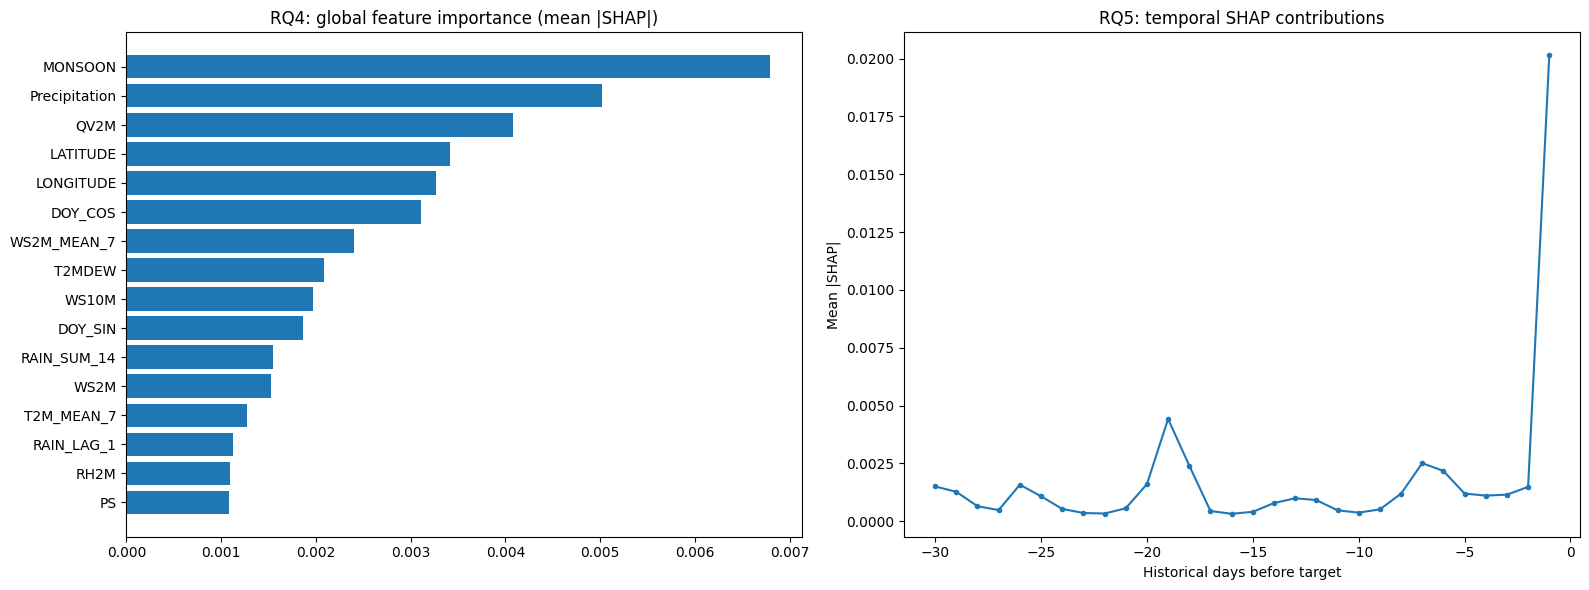

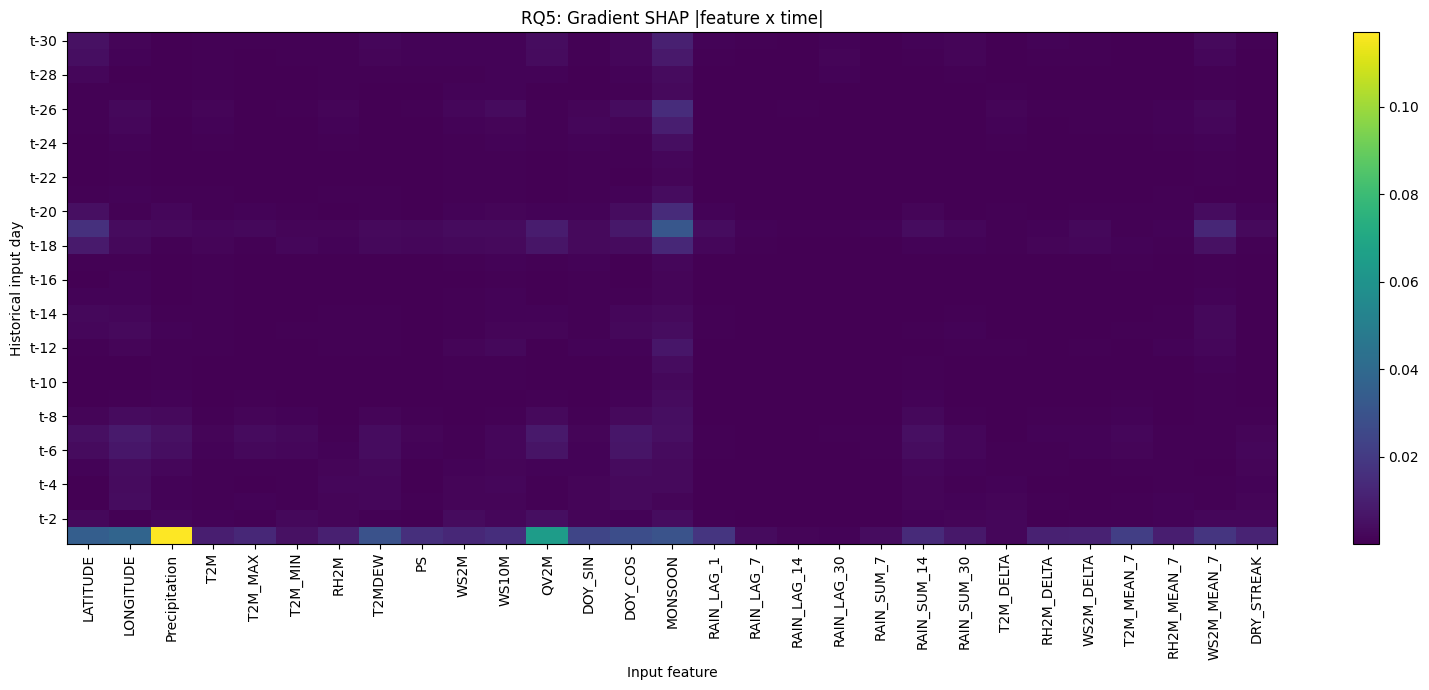

/tmp/ipykernel_22/759934226.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(signed_by_feature,feature_values,feature_names=features,show=False,max_display=16)


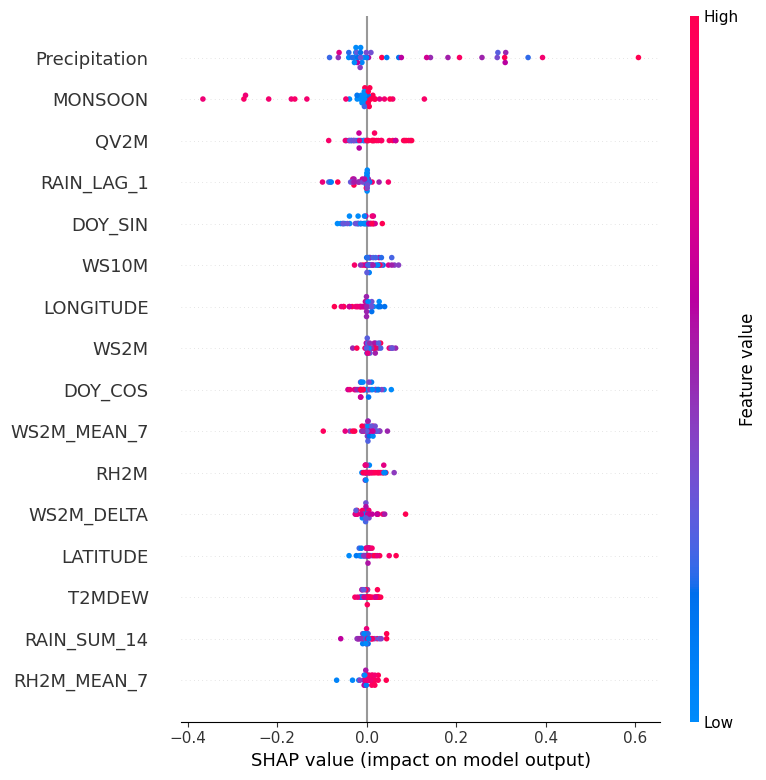

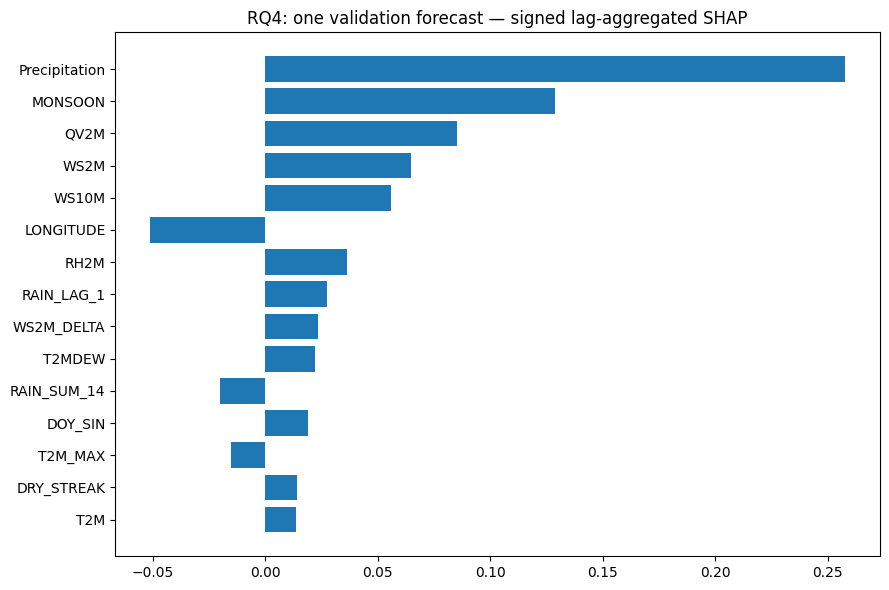

SHAP samples: (40, 30, 29) positive: 20 negative: 20


In [17]:
# Genuine Gradient SHAP from the multi-task Transformer extreme-event output
# Explain 2023 validation samples to avoid repeatedly interpreting/optimizing on the 2024 holdout.
RUN_TEMPORAL_SHAP = True
if RUN_TEMPORAL_SHAP:
    import shap
    explain_model=models['Transformer']
    # Model output from named sigmoid head; use the actual trained weights.
    ext_model=tf.keras.Model(explain_model.input,explain_model.get_layer('ext').output)
    rng=np.random.default_rng(SEED)
    background_idx=rng.choice(np.flatnonzero(train),size=min(32,train.sum()),replace=False)
    pos_idx=np.flatnonzero(val & (y_ext.ravel()==1))
    neg_idx=np.flatnonzero(val & (y_ext.ravel()==0))
    npos=min(20,len(pos_idx)); nneg=min(20,len(neg_idx))
    explanation_idx=np.r_[rng.choice(pos_idx,size=npos,replace=False),rng.choice(neg_idx,size=nneg,replace=False)]
    if len(explanation_idx)<2:raise ValueError('Not enough validation samples to explain')
    background=X[background_idx]; explanation_data=X[explanation_idx]
    explainer=shap.GradientExplainer(ext_model,background)
    sv=explainer.shap_values(explanation_data)
    if isinstance(sv,list):sv=sv[0]
    sv=np.asarray(sv)
    if sv.ndim==4 and sv.shape[-1]==1:sv=sv[...,0]
    if sv.shape!=explanation_data.shape:raise ValueError(f'Unexpected SHAP tensor: {sv.shape} vs {explanation_data.shape}')
    np.save(RQ_OUT/'RQ45_signed_SHAP.npy',sv)
    fi=np.abs(sv).mean(axis=(0,1))
    ti=np.abs(sv).mean(axis=(0,2))
    matrix=np.abs(sv).mean(axis=0)
    pd.DataFrame({'Feature':features,'Mean_abs_SHAP':fi}).sort_values('Mean_abs_SHAP',ascending=False).to_csv(RQ_OUT/'RQ4_global_SHAP_importance.csv',index=False)
    pd.DataFrame({'Historical_day':np.arange(-LOOKBACK,0),'Mean_abs_SHAP':ti}).to_csv(RQ_OUT/'RQ5_time_importance.csv',index=False)
    pd.DataFrame(matrix,index=[f't-{v}' for v in range(LOOKBACK,0,-1)],columns=features).to_csv(RQ_OUT/'RQ5_feature_time_SHAP_matrix.csv')
    fig,axes=plt.subplots(1,2,figsize=(16,6))
    ranking=np.argsort(fi)[-16:]
    axes[0].barh(np.array(features)[ranking],fi[ranking]);axes[0].set_title('RQ4: global feature importance (mean |SHAP|)')
    axes[1].plot(np.arange(-LOOKBACK,0),ti,marker='o',ms=3);axes[1].set(xlabel='Historical days before target',ylabel='Mean |SHAP|',title='RQ5: temporal SHAP contributions')
    fig.tight_layout();fig.savefig(RQ_OUT/'RQ45_global_and_temporal.png',dpi=180);plt.show()
    fig,ax=plt.subplots(figsize=(16,7)); im=ax.imshow(matrix,aspect='auto',cmap='viridis')
    ax.set_yticks(np.arange(0,LOOKBACK,2),[f't-{n}' for n in range(LOOKBACK,0,-1)][::2])
    ax.set_xticks(range(len(features)),features,rotation=90);ax.set(xlabel='Input feature',ylabel='Historical input day',title='RQ5: Gradient SHAP |feature x time|')
    fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(RQ_OUT/'RQ5_temporal_SHAP_heatmap.png',dpi=180);plt.show()
    # Signed SHAP beeswarm on lag-aggregated features (sum contributions across time steps)
    signed_by_feature=sv.sum(axis=1)
    feature_values=explanation_data.mean(axis=1)
    shap.summary_plot(signed_by_feature,feature_values,feature_names=features,show=False,max_display=16)
    plt.gcf().savefig(RQ_OUT/'RQ4_signed_SHAP_summary.png',dpi=180,bbox_inches='tight');plt.show()
    # Individual explanation for the first held-out validation instance; additive approximation caveat
    top_signed=pd.Series(signed_by_feature[0],index=features).sort_values(key=np.abs,ascending=False).head(15)
    fig,ax=plt.subplots(figsize=(9,6));ax.barh(top_signed.index[::-1],top_signed.to_numpy()[::-1]);ax.set_title('RQ4: one validation forecast — signed lag-aggregated SHAP');fig.tight_layout();fig.savefig(RQ_OUT/'RQ4_local_SHAP.png',dpi=180);plt.show()
    print('SHAP samples:',sv.shape,'positive:',npos,'negative:',nneg)


## RQ6 — WARI construction and sensitivity analysis
**Important:** WARI in the thesis is a proposed proxy derived from predicted hazards, not a crop-yield-validated agricultural risk index. This section checks how the predicted classifications change when component weights and high-risk thresholds change. It reports an internal weather-hazard screening diagnostic, **not validation against agricultural losses**. All quantile normalizers below are fit using training observations and are specified transparently.

Risk_category                            High    Low  Moderate
Weights          Thresholds                                   
Dry_heat_focused Higher_high_threshold  0.000  0.950     0.050
                 Lower_high_threshold   0.001  0.746     0.253
                 Reference              0.000  0.782     0.218
Equal_weight     Higher_high_threshold  0.000  0.941     0.059
                 Lower_high_threshold   0.014  0.815     0.171
                 Reference              0.000  0.866     0.134
Rain_focused     Higher_high_threshold  0.006  0.928     0.066
                 Lower_high_threshold   0.037  0.892     0.072
                 Reference              0.020  0.903     0.077
Reference        Higher_high_threshold  0.000  0.947     0.053
                 Lower_high_threshold   0.019  0.897     0.084
                 Reference              0.000  0.920     0.080
Wind_focused     Higher_high_threshold  0.000  0.867     0.133
                 Lower_high_threshold   0.033  0.724     0.243
                 Reference              0.011  0.772     0.217

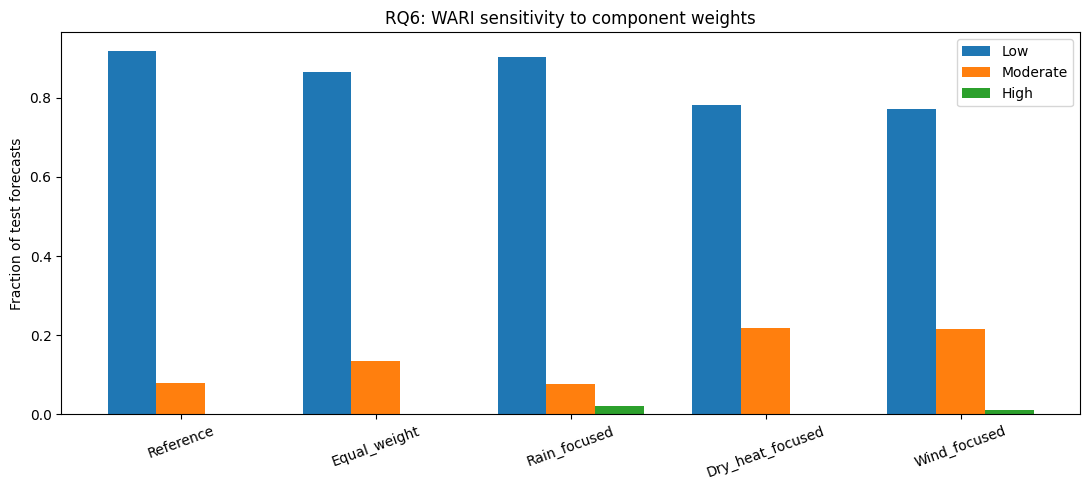

Observed extreme rainfall frequency by forecast WARI score bin:


,count,mean
WARI_Reference,,
"(0.0002899999999999999, 0.0966]",7595,0.006978
"(0.0966, 0.159]",7594,0.017777
"(0.159, 0.218]",7594,0.018699
"(0.218, 0.664]",7595,0.146280


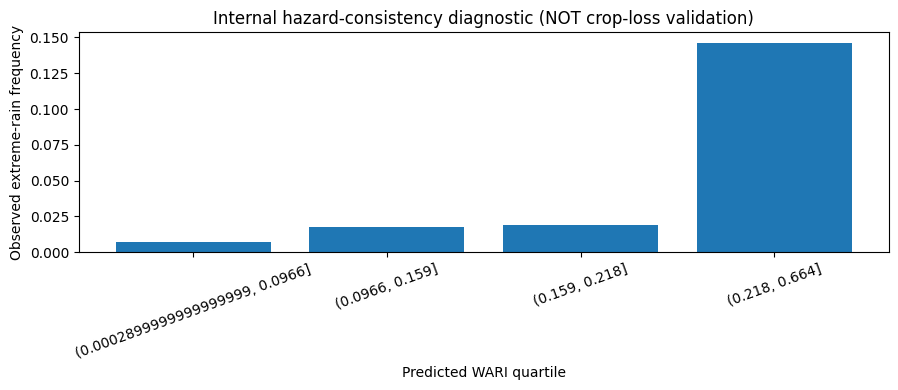

WARI sensitivity output: /kaggle/working/weatherxai_corrected_results/rq3_rq6_evidence


In [18]:
# Construct five weather-hazard components in the same units and order as the original WARI notebook:
# (extreme probability, rainfall intensity, antecedent dryness, heat stress, wind speed)
# Use Transformer predictions for a controlled illustration; the same method applies to any selected model.
chosen='Transformer'
p=predictions[chosen]
phys=inverse_reg(p['reg'])
mtest=meta.loc[test].reset_index(drop=True)
train_sub=full.loc[full.DATE<TRAIN_END]
reference_wind=float(train_sub['WS2M'].quantile(.95))
reference_temp_avg=float(train_sub['T2M'].mean())
reference_temp_std=float(train_sub['T2M'].std())
comp=np.column_stack([
    np.clip(p['ext'].ravel(),0,1),
    np.clip(phys[:,0]/np.maximum(mtest['EXTREME_THRESHOLD'].to_numpy(),1),0,1),
    np.clip(mtest['DRY_STREAK'].to_numpy()/15,0,1)*(1-np.clip(p['occ'].ravel(),0,1)),
    np.clip((phys[:,1]-reference_temp_avg)/(max(reference_temp_std,1e-6)*3),0,1),
    np.clip(phys[:,3]/max(reference_wind,1e-6),0,1)
])
component_names=['Extreme_probability','Rain_intensity','Dryness','Temperature_stress','Wind_hazard']
component_df=pd.DataFrame(comp,columns=component_names)
component_df.to_csv(RQ_OUT/'RQ6_WARI_components.csv',index=False)

weight_scenarios={
 'Reference':np.array([.35,.20,.20,.15,.10]),
 'Equal_weight':np.array([.20,.20,.20,.20,.20]),
 'Rain_focused':np.array([.45,.30,.10,.10,.05]),
 'Dry_heat_focused':np.array([.15,.10,.35,.30,.10]),
 'Wind_focused':np.array([.20,.15,.15,.15,.35])
}
for k,w in weight_scenarios.items():assert np.isclose(w.sum(),1),k
# These are *hypotheses*, not tuned agricultural loss thresholds.
cutoff_scenarios={'Reference':(.33,.66),'Lower_high_threshold':(.30,.55),'Higher_high_threshold':(.40,.75)}
wari_rows=[];detail=mtest[['DATE','LATITUDE','LONGITUDE']].copy()
for wn,w in weight_scenarios.items():
    s=comp@w
    detail['WARI_'+wn]=s
    for tn,(low_cut,high_cut) in cutoff_scenarios.items():
        label=np.where(s>=high_cut,'High',np.where(s>=low_cut,'Moderate','Low'))
        for category in ['Low','Moderate','High']:
            wari_rows.append({'Weights':wn,'Thresholds':tn,'Risk_category':category,
                              'N':int((label==category).sum()),'Fraction':float((label==category).mean())})
summary=pd.DataFrame(wari_rows)
summary.to_csv(RQ_OUT/'RQ6_WARI_sensitivity.csv',index=False)
detail['Observed_extreme_rain'] = y_ext[test].ravel().astype(int)
detail.to_csv(RQ_OUT/'RQ6_WARI_per_sample.csv',index=False)
display(summary.pivot_table(index=['Weights','Thresholds'],columns='Risk_category',values='Fraction').round(3))

fig,ax=plt.subplots(figsize=(11,5))
subset=summary.loc[summary.Thresholds=='Reference']
for category in ['Low','Moderate','High']:
    d=subset[subset.Risk_category==category]
    ax.bar(np.arange(len(weight_scenarios))+['Low','Moderate','High'].index(category)*.25,d.Fraction,width=.25,label=category)
ax.set_xticks(np.arange(len(weight_scenarios))+.25,list(weight_scenarios),rotation=20)
ax.set(ylabel='Fraction of test forecasts',title='RQ6: WARI sensitivity to component weights');ax.legend();fig.tight_layout()
fig.savefig(RQ_OUT/'RQ6_weight_sensitivity.png',dpi=180);plt.show()

# Internal hazard-consistency check — NOT independent agricultural validation
q=np.quantile(detail['WARI_Reference'],[0,.25,.5,.75,1])
q=np.unique(q)
if len(q)>=3:
    bins=pd.cut(detail['WARI_Reference'],bins=q,include_lowest=True,duplicates='drop')
    d=detail.groupby(bins,observed=True)['Observed_extreme_rain'].agg(['count','mean'])
    d.to_csv(RQ_OUT/'RQ6_observed_extreme_by_WARI_bin.csv')
    print('Observed extreme rainfall frequency by forecast WARI score bin:')
    display(d)
    fig,ax=plt.subplots(figsize=(9,4));ax.bar(range(len(d)),d['mean']);ax.set_xticks(range(len(d)),[str(x) for x in d.index],rotation=20)
    ax.set(xlabel='Predicted WARI quartile',ylabel='Observed extreme-rain frequency',title='Internal hazard-consistency diagnostic (NOT crop-loss validation)')
    fig.tight_layout();fig.savefig(RQ_OUT/'RQ6_internal_hazard_consistency.png',dpi=180);plt.show()
print('WARI sensitivity output:', RQ_OUT)


## Reproducibility and paper-ready evidence manifest
**Claims to make only if supported by outputs:** RQ3 multi-task improvement is demonstrated only if corresponding F1/PR-AUC/recall changes justify it; RQ4–RQ5 the SHAP figures explain **model associations, not meteorological causality**, and Gradient SHAP may require environmental compatibility fixes; RQ6 sensitivity tests support transparent hazard-score behavior but **not independent agricultural validity**. To claim agricultural risk validation, obtain crop loss/yield/field impact or expert-labeled agriculture outcome data and conduct a separate external validation.

In [19]:
import zipfile
with open(RQ_OUT/'README_research_evidence.txt','w') as f:
    f.write('RQ3: Same-split rainfall-only Transformer vs event-aware multi-task Transformer. 2023 selects alert thresholds. 2024 test is final evaluation.\n')
    f.write('RQ4/5: GradientExplainer SHAP of extreme-event probability; 32 training backgrounds and 40 stratified 2023 validation samples (pilot). SHAP values are non-causal.\n')
    f.write('RQ6: Illustrative composite weather-hazard score; sensitivity is not crop impact validation. Crop outcome data required for external agricultural validation.\n')
    f.write('References: original WeatherXAI-BD methodology sections 3.9, 3.13, 3.15, 3.16; user-specified 83 complete NASA POWER coordinates 2021-2024.\n')
archive=OUT/'WeatherXAI_BD_RQ3_RQ6_Evidence.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for pp in RQ_OUT.rglob('*'):
        if pp.is_file():z.write(pp,pp.relative_to(OUT))
print('Evidence ZIP ready:',archive)


Evidence ZIP ready: /kaggle/working/weatherxai_corrected_results/WeatherXAI_BD_RQ3_RQ6_Evidence.zip


# Publication-grade additional checks: RQ3–RQ6
These analyses supplement, **not replace**, the earlier steps. RQ3 statistics use geographic-location cluster bootstrap of paired 2024 test predictions. SHAP is checked for output-level local accuracy and event subgroup stability. WARI is compared against observed meteorological events as **internal construct validity**, not independently verified crop losses. Do not use results to retune a final 2024 test set. It is now a used test set: a new holdout is necessary after any changes.

In [20]:
# Supplement configuration and reproducible paper tables
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score
SUP = RQ_OUT / 'publication_checks'
SUP.mkdir(parents=True,exist_ok=True)
BOOTSTRAPS = 1000
BOOT_SEED = 2026
print('Supplement output:',SUP)


Supplement output: /kaggle/working/weatherxai_corrected_results/rq3_rq6_evidence/publication_checks


## RQ3: paired geographical block bootstrap confidence intervals
Resample **locations** (all their test dates together), not individual rows. The two methods are evaluated on exactly the same resampled observations. This preserves within-location time dependence, though it does not eliminate cross-location weather correlation. Confidence intervals are descriptive given the short 2024 testing period.

,Metric,Single_test,Multi_test,Multi_minus_single,CI95_low,CI95_high,CI_excludes_zero
0,precision,0.351695,0.316264,-0.035431,-0.050583,-0.019653,True
1,recall,0.518390,0.608605,0.090215,0.054399,0.125021,True
2,f1,0.419074,0.416232,-0.002843,-0.018618,0.013689,False
3,prauc,0.334478,0.372915,0.038437,0.022855,0.054459,True
4,rocauc,0.913039,0.910023,-0.003017,-0.006976,0.001444,False


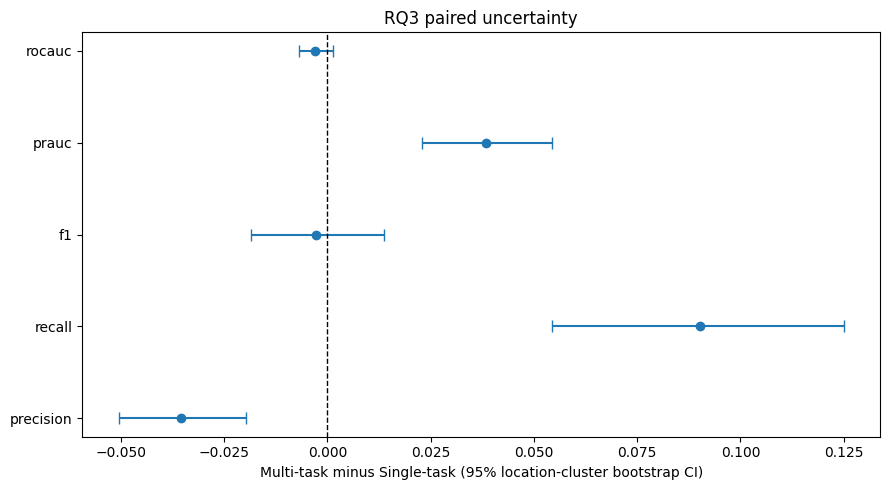

In [21]:
paired=pd.read_csv(RQ_OUT/'RQ3_paired_test_predictions.csv',parse_dates=['DATE'])
required={'LATITUDE','LONGITUDE','actual_extreme','single_score','multi_prob','single_alert','multi_alert'}
assert required.issubset(paired.columns),required-set(paired.columns)
assert paired[['actual_extreme','single_score','multi_prob','single_alert','multi_alert']].notna().all().all()
paired['site_id']=paired.LATITUDE.astype(str)+'_'+paired.LONGITUDE.astype(str)
site_groups={site:idx.to_numpy() for site,idx in paired.groupby('site_id').groups.items()}
sites=np.array(list(site_groups))

def paired_scores(sub):
    y=sub.actual_extreme.to_numpy().astype(int)
    if y.min()==y.max():return None
    o={}
    for method,score,alert in [('single','single_score','single_alert'),('multi','multi_prob','multi_alert')]:
        p=sub[score].to_numpy(); z=sub[alert].to_numpy().astype(int)
        o[f'{method}_precision']=precision_score(y,z,zero_division=0)
        o[f'{method}_recall']=recall_score(y,z,zero_division=0)
        o[f'{method}_f1']=f1_score(y,z,zero_division=0)
        o[f'{method}_prauc']=average_precision_score(y,p)
        o[f'{method}_rocauc']=roc_auc_score(y,p)
    for m in ['precision','recall','f1','prauc','rocauc']:
        o['delta_'+m]=o['multi_'+m]-o['single_'+m]
    return o

point=paired_scores(paired); assert point is not None
rng=np.random.default_rng(BOOT_SEED); bootstrap=[]
for iteration in range(BOOTSTRAPS):
    sampled_sites=rng.choice(sites,size=len(sites),replace=True)
    ids=np.concatenate([site_groups[x] for x in sampled_sites])
    out=paired_scores(paired.iloc[ids])
    if out is not None:bootstrap.append(out)
bs=pd.DataFrame(bootstrap)
rows=[]
for metric in ['precision','recall','f1','prauc','rocauc']:
    key='delta_'+metric;lo,hi=np.quantile(bs[key],[.025,.975])
    rows.append({'Metric':metric,'Single_test':point['single_'+metric],
                 'Multi_test':point['multi_'+metric],
                 'Multi_minus_single':point[key],
                 'CI95_low':lo,'CI95_high':hi,
                 'CI_excludes_zero':bool(lo>0 or hi<0)})
ci=pd.DataFrame(rows)
ci.to_csv(SUP/'RQ3_paired_cluster_bootstrap_CI.csv',index=False)
display(ci)
fig,ax=plt.subplots(figsize=(9,5))
xx=np.arange(len(ci));ax.errorbar(ci.Multi_minus_single,xx,xerr=[ci.Multi_minus_single-ci.CI95_low,ci.CI95_high-ci.Multi_minus_single],fmt='o',capsize=4)
ax.axvline(0,color='black',ls='--',lw=1);ax.set_yticks(xx,ci.Metric);ax.set(xlabel='Multi-task minus Single-task (95% location-cluster bootstrap CI)',title='RQ3 paired uncertainty');fig.tight_layout()
fig.savefig(SUP/'RQ3_cluster_bootstrap_CI.png',dpi=200);plt.show()


## RQ4–RQ5: SHAP reliability, local accuracy and extreme-versus-normal temporal patterns
Gradient SHAP is a Monte Carlo approximation; attribution is not causal. The extreme/non-extreme groups below refer to **2023 validation labels**. This cell relies on the trained Transformer and variables from the original notebook. Repeated explanations with independent backgrounds are used as a stability diagnostic. Note that chronological dependence can make ordinary feature masking unrealistic.

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(60, 30, 29))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 30, 29))']
  warnings.warn(msg)


Gradient SHAP approximation |prediction - base - sum(SHAP)|: count    60.000000
mean      0.027456
std       0.019963
min       0.000108
25%       0.013632
50%       0.027111
75%       0.040245
max       0.086432
Name: Absolute_additivity_error, dtype: float64
Two-background attribution stability Pearson r: 0.9937614213966517


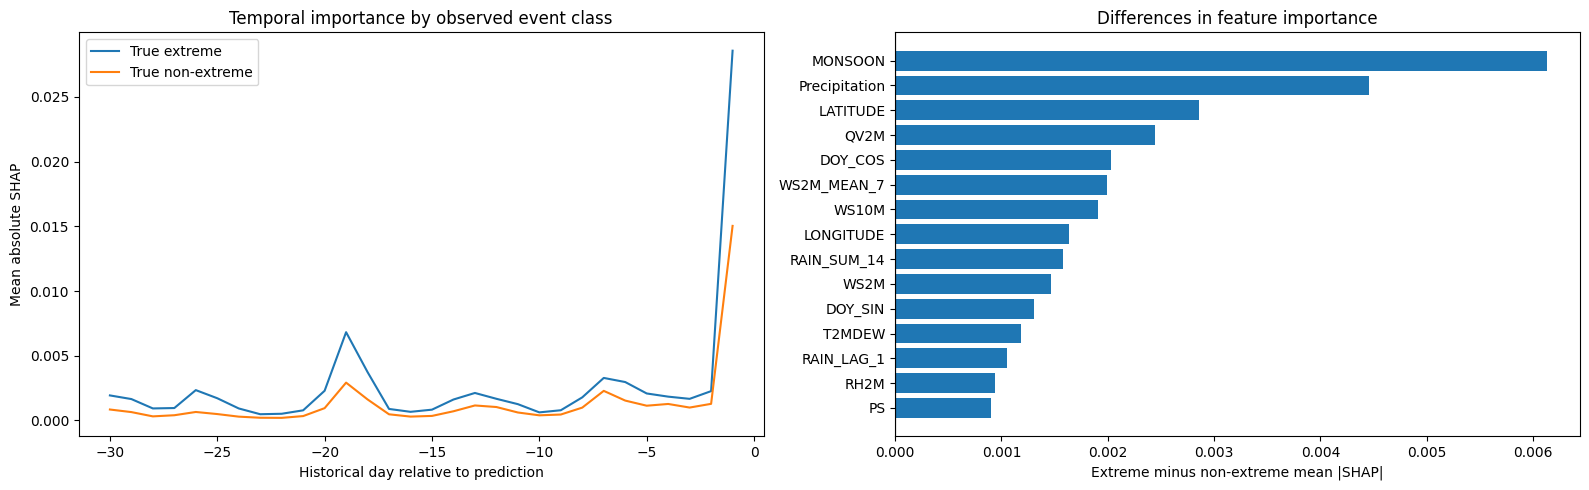

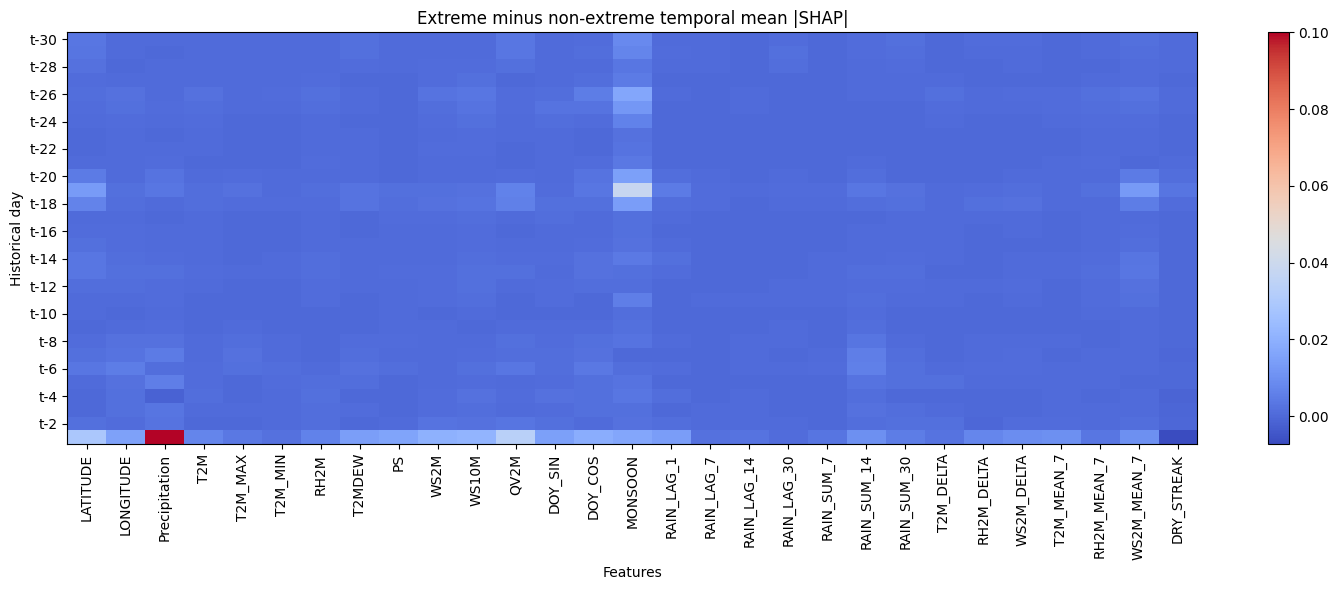

In [22]:
# New validation explanation samples; do not calculate SHAP on post-hoc selected test errors.
import shap
assert 'models' in globals() and 'Transformer' in models, 'Run the model-training cells first.'
explain_net=tf.keras.Model(models['Transformer'].input,models['Transformer'].get_layer('ext').output)
rng=np.random.default_rng(54321)
train_indices=np.flatnonzero(train)
val_pos=np.flatnonzero(val & (y_ext.ravel()==1))
val_neg=np.flatnonzero(val & (y_ext.ravel()==0))
assert len(val_pos)>=12 and len(val_neg)>=12, 'Insufficient validation events'
selected_pos=rng.choice(val_pos,size=min(30,len(val_pos)),replace=False)
selected_neg=rng.choice(val_neg,size=min(30,len(val_neg)),replace=False)
selected=np.r_[selected_pos,selected_neg]; samples=X[selected]

def get_gradient_shap(background_ids):
    expl=shap.GradientExplainer(explain_net,X[background_ids])
    values=expl.shap_values(samples)
    if isinstance(values,list):values=values[0]
    values=np.asarray(values)
    if values.ndim==4 and values.shape[-1]==1:values=values[...,0]
    if values.shape!=samples.shape:raise RuntimeError(f'Unexpected SHAP shape {values.shape}')
    return values

bg1=rng.choice(train_indices,size=min(48,len(train_indices)),replace=False)
bg2=rng.choice(train_indices,size=min(48,len(train_indices)),replace=False)
sv1=get_gradient_shap(bg1);sv2=get_gradient_shap(bg2)
np.save(SUP/'RQ45_SHAP_grouped_signed.npy',sv1)
expected1=float(explain_net.predict(X[bg1],verbose=0).mean())
prob=explain_net.predict(samples,verbose=0).ravel()
approx=expected1+sv1.sum(axis=(1,2))
local_error=np.abs(prob-approx)
check=pd.DataFrame({'Class':np.r_[np.ones(len(selected_pos),dtype=int),np.zeros(len(selected_neg),dtype=int)],
                    'Predicted_probability':prob,'GradientSHAP_reconstruction':approx,'Absolute_additivity_error':local_error})
check.to_csv(SUP/'RQ45_SHAP_local_accuracy.csv',index=False)
print('Gradient SHAP approximation |prediction - base - sum(SHAP)|:',check.Absolute_additivity_error.describe())
A=np.abs(sv1).mean(axis=0);B=np.abs(sv2).mean(axis=0)
corr=float(np.corrcoef(A.ravel(),B.ravel())[0,1]) if A.std()>0 and B.std()>0 else np.nan
print('Two-background attribution stability Pearson r:',corr)

n_pos=len(selected_pos);e=np.abs(sv1[:n_pos]).mean(axis=0);non=np.abs(sv1[n_pos:]).mean(axis=0)
pd.DataFrame({'Feature':features,'Mean_abs_SHAP_extreme':e.mean(axis=0),'Mean_abs_SHAP_nonextreme':non.mean(axis=0),
              'Difference':e.mean(axis=0)-non.mean(axis=0)}).sort_values('Difference',ascending=False).to_csv(SUP/'RQ45_extreme_vs_nonextreme_features.csv',index=False)
pd.DataFrame({'Lag':np.arange(-LOOKBACK,0),'Extreme':e.mean(axis=1),'NonExtreme':non.mean(axis=1)}).to_csv(SUP/'RQ5_extreme_vs_nonextreme_lags.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(16,5))
axes[0].plot(np.arange(-LOOKBACK,0),e.mean(axis=1),label='True extreme')
axes[0].plot(np.arange(-LOOKBACK,0),non.mean(axis=1),label='True non-extreme')
axes[0].set(xlabel='Historical day relative to prediction',ylabel='Mean absolute SHAP',title='Temporal importance by observed event class');axes[0].legend()
feature_diffs=(e-non).mean(axis=0);inds=np.argsort(np.abs(feature_diffs))[-15:]
axes[1].barh(np.array(features)[inds],feature_diffs[inds]);axes[1].axvline(0,c='black',lw=.8)
axes[1].set(xlabel='Extreme minus non-extreme mean |SHAP|',title='Differences in feature importance')
fig.tight_layout();fig.savefig(SUP/'RQ45_extreme_vs_nonextreme_SHAP.png',dpi=200);plt.show()
fig,ax=plt.subplots(figsize=(15,6));im=ax.imshow(e-non,cmap='coolwarm',aspect='auto')
ax.set_xticks(np.arange(len(features)),features,rotation=90)
ax.set_yticks(np.arange(0,LOOKBACK,2),[f't-{k}' for k in range(LOOKBACK,0,-1)][::2]);ax.set(title='Extreme minus non-extreme temporal mean |SHAP|',xlabel='Features',ylabel='Historical day')
fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(SUP/'RQ5_group_difference_heatmap.png',dpi=200);plt.show()
with open(SUP/'RQ45_diagnostics.txt','w') as f:
    f.write(f'GradientSHAP background stability Pearson r: {corr:.5f}\n')
    f.write(f'Mean absolute local reconstruction error: {local_error.mean():.6f}\n')
    f.write('These are pilot attribution reliability diagnostics, not statistical proof of physical causality.\n')


## RQ6: construct validity, WARI discrimination and sensitivity
An agricultural *outcome* has not been provided, so independent agricultural validation cannot be performed. This section evaluates only whether forecast WARI is associated with **observed extreme precipitation**, a component-related meteorological outcome. This can be partly circular because predicted extreme probability is included in WARI. Thus it is an internal hazard-consistency test, **not** proof of actual crop impact. Compare each score with the raw extreme-event probability to check whether the composite adds usable information.

,Score,ROC_AUC_extreme,PR_AUC_extreme,Spearman_risk_event
2,WARI_Rain_focused,0.898330,0.389659,0.293314
5,Transformer_extreme_probability,0.910023,0.372915,0.301924
0,WARI_Reference,0.840775,0.352386,0.250933
1,WARI_Equal_weight,0.812745,0.309148,0.230293
4,WARI_Wind_focused,0.801604,0.275052,0.222089
3,WARI_Dry_heat_focused,0.636386,0.062688,0.100429


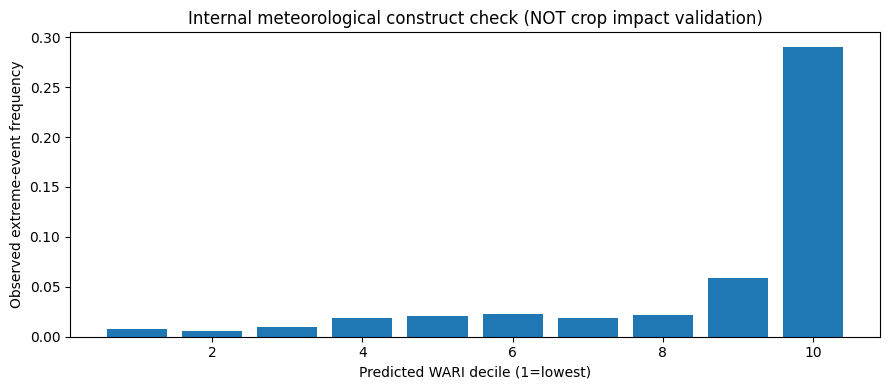

Sensitivity scenarios: 15


Risk_category                               High       Low  Moderate
Weights          Thresholds                                         
Dry_heat_focused Higher_high_threshold  0.000000  0.950260  0.049740
                 Lower_high_threshold   0.000691  0.746297  0.253012
                 Reference              0.000000  0.781849  0.218151
Equal_weight     Higher_high_threshold  0.000000  0.941175  0.058825
                 Lower_high_threshold   0.014122  0.814833  0.171045
                 Reference              0.000000  0.866186  0.133814
Rain_focused     Higher_high_threshold  0.005794  0.928402  0.065804
                 Lower_high_threshold   0.036704  0.891599  0.071697
                 Reference              0.020047  0.903450  0.076503
Reference        Higher_high_threshold  0.000000  0.946869  0.053131
                 Lower_high_threshold   0.018665  0.897130  0.084206
                 Reference              0.000066  0.919613  0.080321
Wind_focused     Higher_high_threshold  0.000000  0.867305  0.132695
                 Lower_high_threshold   0.032886  0.724142  0.242972
                 Reference              0.010863  0.772269  0.216867

In [23]:
wari=pd.read_csv(RQ_OUT/'RQ6_WARI_per_sample.csv',parse_dates=['DATE'])
assert {'WARI_Reference','Observed_extreme_rain'}.issubset(wari.columns)
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
Y_obs=wari.Observed_extreme_rain.astype(int).to_numpy()
rows=[]
for column in [x for x in wari.columns if x.startswith('WARI_')]:
    scores=wari[column].astype(float).to_numpy()
    rows.append({'Score':column,'ROC_AUC_extreme':roc_auc_score(Y_obs,scores),
                 'PR_AUC_extreme':average_precision_score(Y_obs,scores),
                 'Spearman_risk_event':pd.Series(scores).corr(pd.Series(Y_obs),method='spearman')})
# Extreme probability is the reference discriminative predictor
transformer_ext=np.asarray(predictions['Transformer']['ext']).ravel()
assert len(transformer_ext)==len(wari)
rows.append({'Score':'Transformer_extreme_probability','ROC_AUC_extreme':roc_auc_score(Y_obs,transformer_ext),
             'PR_AUC_extreme':average_precision_score(Y_obs,transformer_ext),
             'Spearman_risk_event':pd.Series(transformer_ext).corr(pd.Series(Y_obs),method='spearman')})
index_metrics=pd.DataFrame(rows).sort_values('PR_AUC_extreme',ascending=False)
index_metrics.to_csv(SUP/'RQ6_internal_construct_metrics.csv',index=False)
display(index_metrics)
# Decile risk concentration: monotonicity check, actual frequency by WARI decile
risk=wari.WARI_Reference.astype(float)
rank_bins=pd.qcut(risk.rank(method='first'),10,labels=False)
checks=pd.DataFrame({'Decile':rank_bins+1,'Observed_extreme':Y_obs,'WARI':risk}).groupby('Decile').agg(
  n=('Observed_extreme','size'),observed_extreme_rate=('Observed_extreme','mean'),mean_WARI=('WARI','mean')).reset_index()
checks.to_csv(SUP/'RQ6_observed_extreme_by_decile.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4));ax.bar(checks.Decile,checks.observed_extreme_rate)
ax.set(xlabel='Predicted WARI decile (1=lowest)',ylabel='Observed extreme-event frequency',
       title='Internal meteorological construct check (NOT crop impact validation)')
fig.tight_layout();fig.savefig(SUP/'RQ6_extreme_event_by_WARI_decile.png',dpi=200);plt.show()
# Sensitivity uncertainty: each scenario risk-level distribution is already in RQ6_WARI_sensitivity.csv
sensitivity=pd.read_csv(RQ_OUT/'RQ6_WARI_sensitivity.csv')
print('Sensitivity scenarios:',sensitivity[['Weights','Thresholds']].drop_duplicates().shape[0])
pivot=sensitivity.pivot_table(index=['Weights','Thresholds'],columns='Risk_category',values='Fraction')
display(pivot)
# Check whether no high-risk forecasts are produced under some scenarios
sensitivity.loc[(sensitivity.Risk_category=='High')&(sensitivity.N==0)].to_csv(SUP/'RQ6_zero_high_risk_scenarios.csv',index=False)


## Chapter 4 evidence and reporting guide
**RQ3:** Report paired test metrics and uncertainty. Cite event-aware gains ONLY for metrics with positive observed differences; describe the precision/recall trade-off and whether uncertainty includes zero. The change in PR-AUC is not by itself proof of significant superiority.

**RQ4:** Explain exactly which model head was interpreted (Transformer extreme-event probability), the GradientExplainer background distribution, sample count, and whether SHAP reconstructs model outputs approximately. Interpret associations, not causality.

**RQ5:** Report signed (directional) and absolute (importance) contributions separately; show extreme versus non-extreme lag heatmaps. Note the scope is a selected, stratified 2023 validation sample, not necessarily representative globally.

**RQ6:** Report the score definition, components, weights and category cutoffs; conduct sensitivity checks. Without crop yield, damage or agricultural outcomes, describe this as internal *meteorological* construct validity, not independent agricultural validation. A crop-impact dataset aligned by location/date and harvest calendar is required to claim real agricultural risk prediction.

**General:** Your 2024 test set has already been examined; after any choices are revised because of this test performance, evaluate on an additional chronologically later untouched holdout, if available. Run several random seeds, and state uncertainty, dataset coverage (83 locations), NASA POWER gridded-source limitations and method-specific constraints.

In [24]:
# Export supplementary evidence in one ZIP (run after all cells)
import zipfile
bundle=OUT/'WeatherXAI_RQ3_to_RQ6_Publication_Evidence.zip'
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as arc:
    for root in [RQ_OUT,SUP]:
        for p in root.rglob('*'):
            if p.is_file():arc.write(p,p.relative_to(OUT))
print('Evidence bundle:',bundle)


Evidence bundle: /kaggle/working/weatherxai_corrected_results/WeatherXAI_RQ3_to_RQ6_Publication_Evidence.zip


/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'rq3_rq6_evidence/publication_checks/RQ6_zero_high_risk_scenarios.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'rq3_rq6_evidence/publication_checks/RQ5_group_difference_heatmap.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'rq3_rq6_evidence/publication_checks/RQ5_extreme_vs_nonextreme_lags.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'rq3_rq6_evidence/publication_checks/RQ3_paired_cluster_bootstrap_CI.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'rq3_rq6_evidence/publication_checks/RQ45_SHAP_grouped_signed.npy'
  return self._open_to_wr

In [25]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED, BadZipFile

# Main output folder
SOURCE_DIR = Path(
    "/kaggle/working/weatherxai_corrected_results"
)

# Final ZIP file
ZIP_PATH = Path(
    "/kaggle/working/WeatherXAI_RQ3_to_RQ6_Publication_Evidence.zip"
)

if not SOURCE_DIR.exists():
    raise FileNotFoundError(
        f"Results folder not found: {SOURCE_DIR}"
    )

# Find all files recursively, without duplicates
files = sorted({
    p.resolve()
    for p in SOURCE_DIR.rglob("*")
    if p.is_file()
    and p.resolve() != ZIP_PATH.resolve()
})

print("Total unique files:", len(files))

# Always overwrite old ZIP instead of appending to it
with ZipFile(ZIP_PATH, mode="w", compression=ZIP_DEFLATED,
             compresslevel=6) as zipf:

    for file_path in files:
        # Preserve relative folder structure
        archive_name = file_path.relative_to(
            SOURCE_DIR.resolve()
        )

        zipf.write(
            filename=file_path,
            arcname=str(archive_name)
        )

# Verify ZIP contents
with ZipFile(ZIP_PATH, "r") as zipf:
    names = zipf.namelist()
    bad_file = zipf.testzip()

    print("\n===== ZIP VERIFICATION =====")
    print("Total files:", len(names))
    print("Unique names:", len(set(names)))
    print("Duplicate names:",
          len(names) - len(set(names)))
    print("Corrupted file:", bad_file)

    assert len(names) == len(set(names)), \
        "Duplicate ZIP entries detected"

    assert bad_file is None, \
        f"Corrupted ZIP entry: {bad_file}"

print("\nZIP successfully created!")
print("File:", ZIP_PATH)
print("Size (MB):",
      round(ZIP_PATH.stat().st_size / (1024**2), 2))


Total unique files: 80

===== ZIP VERIFICATION =====
Total files: 80
Unique names: 80
Duplicate names: 0
Corrupted file: None

ZIP successfully created!
File: /kaggle/working/WeatherXAI_RQ3_to_RQ6_Publication_Evidence.zip
Size (MB): 41.2
